# B — Clustering kejadian & penamaan kelas (Fahmi) — v2

Notebook bagian B, Task 2 Datavidia 11.0.

**Alur v2:** embedding DINOv2-L FP32 (`hafizh/v3.1`, cabang warna) → PCA → Spectral Clustering per kejadian → gate kualitas →
median 6 sumbu indikator per cluster → z-score robust → bobot sumbu = reliabilitas split-half →
skor 6 kelas dari `rules.json` v2 (desain D2b, dikunci Fahmi) → nama kejadian → keyakinan bootstrap → `is_core` & `weight`.

**Output** (`v2/`, tidak menimpa `v1/`): `events.parquet`, `event_names.csv`, `cluster_profile.csv`, `bobot_sumbu.csv`,
`ketahanan_sumbu.csv`, `rules.json`, `meta.json`.

**Keterangan aturan:** aturan penamaan (`rules.json` v2, desain D2b) disusun dari deskripsi resmi kelas panitia
**dengan bantuan AI (Claude)**, dikunci oleh Fahmi, dan **dijalankan seluruhnya oleh kode**. Bobot sumbu, z-score,
dan keyakinan dihitung otomatis dari data tanpa label. Tidak ada label manual, tidak ada penilaian visual gambar,
dan aturan tidak disetel berdasarkan nama cluster yang dihasilkan.

## Pilih bagian yang dijalankan
Bagian v2 sudah selesai (output di `v2/`). Dengan `JALANKAN_V2 = False`, sel v2 (bertanda `%%jika_v2`) dilewati saat *Run All*,
sehingga hanya **STRATEGI v3** di bagian bawah yang dijalankan. Isi dan output lama sel v2 tidak diubah.

In [1]:
# True = jalankan ulang bagian v2 (akan membuat folder versi baru, tidak menimpa v2/)
JALANKAN_V2 = False

from IPython.core.magic import register_cell_magic

@register_cell_magic
def jika_v2(line, cell):
    # sel bertanda %%jika_v2 hanya dijalankan jika JALANKAN_V2 = True
    if JALANKAN_V2:
        get_ipython().run_cell(cell)
    else:
        print("Dilewati (JALANKAN_V2 = False)")

## 0. Library & versi

In [1]:
import json, os, sys, platform
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.cluster import SpectralClustering, KMeans
from sklearn.metrics import adjusted_rand_score

# Versi library dicatat untuk meta.json
VERSI_LIB = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pyarrow": pyarrow.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
for k, v in VERSI_LIB.items():
    print(f"{k:13s} {v}")

python        3.12.7
numpy         2.5.5
pandas        3.1.1
pyarrow       26.0.1
scipy         1.18.1
scikit-learn  1.9.1
matplotlib    3.10.9


## Pengaturan
Semua path dan angka di sini. Path relatif terhadap folder `fahmi/`.

In [2]:
%%jika_v2
# --- Path input ---
SAMPLE_SUB = "../../sample_submission.csv"      # di luar repo
FITUR_DIR  = "../hafizh/v3.1"                   # DINOv2-L FP32 deterministik
PHYS_PATH  = "../hafizh/v3.1/phys_v4.parquet"   # ambang color_shift 24
V1_DIR     = "v1"                               # pembanding (hanya dibaca)

# --- Output (jika sudah ada, notebook memakai v3, v4, ... ; tidak menimpa) ---
OUTPUT_DIR = "v2"

# --- Embedding & clustering ---
SEED = 42
PCA_DIM = 64            # dimensi PCA
ROUND = 4               # pembulatan embedding sebelum clustering
K = 20                  # jumlah cluster kejadian (spectral)
KNN = 15                # n_neighbors graf spectral
K_KASAR = 8             # KMeans struktur kasar (pengecekan saja)
NOISE_SKALA = 1e-3      # std noise = NOISE_SKALA x std(Z), untuk uji ketahanan

# --- Penamaan, keyakinan, is_core ---
MIN_WARNA = 15          # minimal foto warna valid per cluster untuk indikator air
N_SPLIT_REL = 20        # jumlah pembagian acak untuk reliabilitas split-half
N_BOOT = 200            # jumlah bootstrap untuk keyakinan nama
YAKIN_MIN = 0.6         # cluster lemah jika keyakinan < 0.6
CORE_FRAC_KUAT = 0.5    # porsi foto terdekat pusat untuk cluster kuat
CORE_FRAC_LEMAH = 0.2   # porsi untuk cluster lemah
MIN_CORE_KELAS = 30     # minimal foto is_core per kelas

# --- Gate kualitas ---
KNN_UJI = 25            # n_neighbors untuk uji ketahanan parameter
GATE_ARI_NOISE = 0.95
GATE_ARI_KNN = 0.80
GATE_BIAS_MAX = 0.15
GATE_MIN_SIZE = 30

np.random.seed(SEED)
print("Folder kerja:", os.getcwd())
for p in [SAMPLE_SUB, FITUR_DIR, PHYS_PATH, V1_DIR]:
    print(f"{'ada ' if os.path.exists(p) else 'TIDAK ADA'}  {p}")

Folder kerja: d:\Python\Library\Scikit-learn\praktik kaggle\Arkavidia\Task2\Perintis_DATAVIDIA\fahmi
ada   ../../sample_submission.csv
ada   ../hafizh/v3.1
ada   ../hafizh/v3.1/phys_v4.parquet
ada   v1


## 1. Muat data & cek input

In [3]:
%%jika_v2
sub   = pd.read_csv(SAMPLE_SUB)
art   = pd.read_parquet(f"{FITUR_DIR}/artifact_and_phys_v3.parquet")
patch = pd.read_parquet(f"{FITUR_DIR}/patch_change_stats_v3.parquet")
phys  = pd.read_parquet(PHYS_PATH)
emb_pre  = np.load(f"{FITUR_DIR}/dino_color_pre.npy")
emb_post = np.load(f"{FITUR_DIR}/dino_color_post.npy")
with open(f"{FITUR_DIR}/meta.json", encoding="utf-8") as f:
    META_A = json.load(f)

ids = sub["Id"].to_numpy()
N = len(ids)

# Cek urutan Id sama persis dengan sample_submission
for nama, df in [("artifact", art), ("patch", patch), ("phys_v4", phys)]:
    assert len(df) == N and (df["Id"].to_numpy() == ids).all(), f"urutan Id {nama} berbeda"
assert sub["Id"].is_unique

# Cek embedding
for nama, e in [("pre", emb_pre), ("post", emb_post)]:
    assert e.shape == (N, 1024), f"bentuk {nama} {e.shape}"
    assert not np.isnan(e).any(), f"NaN di embedding {nama}"

print("Input A:", META_A["versi"], "|", META_A["pengaturan"]["backbone"], "|", META_A["pengaturan"]["precision"],
      "| ambang color_shift:", META_A["pengaturan"].get("ambang_color_shift"))
print("N =", N, "| embedding pre/post:", emb_pre.shape, emb_post.shape, emb_pre.dtype)
print("artifact:", art.shape, "| patch:", patch.shape, "| phys_v4:", phys.shape)
print("color_unreliable_v4 =", round(phys["color_unreliable_v4"].mean() * 100, 1), "% foto")
print("Semua cek urutan Id, bentuk, dan NaN embedding: LULUS")

Input A: v3.1 | vit_large_patch14_dinov2.lvd142m | fp32 | ambang color_shift: 24.0
N = 3180 | embedding pre/post: (3180, 1024) (3180, 1024) float32
artifact: (3180, 47) | patch: (3180, 28) | phys_v4: (3180, 23)
color_unreliable_v4 = 64.6 % foto
Semua cek urutan Id, bentuk, dan NaN embedding: LULUS


## 2. Siapkan embedding
L2 per blok → gabung pre+post (2048) → kurangi rata-rata → PCA → bulatkan.

In [4]:
%%jika_v2
pre  = emb_pre.astype(np.float64)
post = emb_post.astype(np.float64)
pre  = pre  / np.linalg.norm(pre,  axis=1, keepdims=True)    # L2 per blok
post = post / np.linalg.norm(post, axis=1, keepdims=True)

X = np.hstack([pre, post])          # (3180, 2048)
X = X - X.mean(axis=0)              # kurangi rata-rata kolom

pca = PCA(PCA_DIM, random_state=SEED)
Z = np.round(pca.fit_transform(X), ROUND)    # dibulatkan sebelum clustering

evr = pca.explained_variance_ratio_
print("Z:", Z.shape)
print(f"Variansi dijelaskan PCA {PCA_DIM}: {evr.sum():.3f}  (10 komponen pertama: {evr[:10].sum():.3f})")

Z: (3180, 64)
Variansi dijelaskan PCA 64: 0.816  (10 komponen pertama: 0.579)


## 3. Clustering
Utama: Spectral (K kejadian). Struktur kasar: KMeans k = K_KASAR (pengecekan saja).

C:\Users\AcerPredatorHelios16\anaconda3\envs\env_general\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=13.
  warnings.warn(


Ukuran cluster kejadian: {0: 40, 1: 45, 2: 61, 3: 116, 4: 112, 5: 101, 6: 58, 7: 116, 8: 172, 9: 193, 10: 129, 11: 136, 12: 142, 13: 193, 14: 174, 15: 207, 16: 214, 17: 248, 18: 375, 19: 348}
Ukuran struktur kasar  : {0: 480, 1: 557, 2: 530, 3: 225, 4: 476, 5: 176, 6: 326, 7: 410}


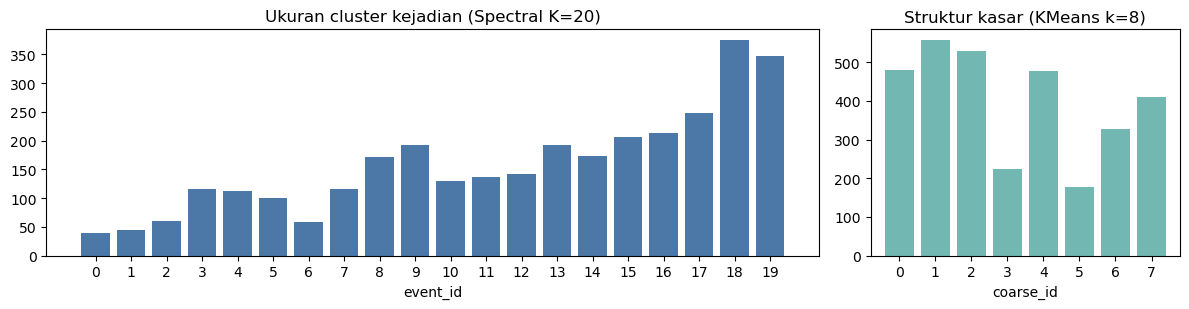

In [5]:
%%jika_v2
sc = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN,
                        assign_labels="cluster_qr", random_state=SEED)
event_id = sc.fit_predict(Z)

km = KMeans(K_KASAR, n_init=10, random_state=SEED)
coarse_id = km.fit_predict(Z)

ukuran = pd.Series(event_id).value_counts().sort_index()
ukuran_kasar = pd.Series(coarse_id).value_counts().sort_index()
print("Ukuran cluster kejadian:", ukuran.to_dict())
print("Ukuran struktur kasar  :", ukuran_kasar.to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [K, K_KASAR]})
ax[0].bar(ukuran.index, ukuran.values, color="#4C78A8")
ax[0].set_title(f"Ukuran cluster kejadian (Spectral K={K})"); ax[0].set_xlabel("event_id"); ax[0].set_xticks(ukuran.index)
ax[1].bar(ukuran_kasar.index, ukuran_kasar.values, color="#72B7B2")
ax[1].set_title(f"Struktur kasar (KMeans k={K_KASAR})"); ax[1].set_xlabel("coarse_id"); ax[1].set_xticks(ukuran_kasar.index)
plt.tight_layout(); plt.show()

## 4. Gate kualitas
Jika ada cek yang GAGAL, notebook berhenti di sini (ubah K / PCA, jangan lanjut).

η² = Σ n_c (mean_c − mean)² / Σ (x − mean)²  — porsi variasi yang dijelaskan pembagian cluster.

In [6]:
%%jika_v2
def eta2(label, x):
    # eta kuadrat; baris NaN dilewati
    x = np.asarray(x, dtype=float); ok = ~np.isnan(x)
    lab, x = np.asarray(label)[ok], x[ok]
    m = x.mean(); total = ((x - m) ** 2).sum()
    antar = sum((lab == c).sum() * (x[lab == c].mean() - m) ** 2 for c in np.unique(lab))
    return antar / total if total > 0 else 0.0

# 1) Ketahanan noise: noise normal (std = NOISE_SKALA x std(Z)), seed tetap -> bulatkan -> cluster ulang
rng = np.random.default_rng(SEED)
Z_noise = np.round(Z + rng.normal(0, NOISE_SKALA * Z.std(), Z.shape), ROUND)
lab_noise = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN,
                               assign_labels="cluster_qr", random_state=SEED).fit_predict(Z_noise)
ari_noise = adjusted_rand_score(event_id, lab_noise)

# 2) Ketahanan parameter: n_neighbors = KNN_UJI
lab_knn = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN_UJI,
                             assign_labels="cluster_qr", random_state=SEED).fit_predict(Z)
ari_knn = adjusted_rand_score(event_id, lab_knn)

# 3) Bias artefak
artefak = {
    "is_gray (pre+post)":        art["is_gray_pre"].astype(float) + art["is_gray_post"].astype(float),
    "black_frac (pre+post)":     art["black_frac_pre"] + art["black_frac_post"],
    "scanline_score (pre+post)": art["scanline_score_pre"] + art["scanline_score_post"],
    "color_shift":               phys["color_shift"],
    "|brightness post-pre|":     (art["brightness_post"] - art["brightness_pre"]).abs(),
}
bias = pd.Series({k: eta2(event_id, v) for k, v in artefak.items()}, name="eta2").round(4)
print("η² event_id vs artefak:"); print(bias.to_string(), "\n")

# 4) Ukuran cluster terkecil
min_size = int(ukuran.min())

gate = pd.DataFrame({
    "nilai":  [ari_noise, ari_knn, bias.max(), min_size],
    "target": [f">= {GATE_ARI_NOISE}", f">= {GATE_ARI_KNN}", f"<= {GATE_BIAS_MAX}", f">= {GATE_MIN_SIZE}"],
    "lulus":  [ari_noise >= GATE_ARI_NOISE, ari_knn >= GATE_ARI_KNN,
               bias.max() <= GATE_BIAS_MAX, min_size >= GATE_MIN_SIZE],
}, index=["ARI noise", f"ARI kNN={KNN_UJI}", f"bias maks ({bias.idxmax()})", "ukuran min"])
gate["status"] = np.where(gate["lulus"], "LULUS", "GAGAL")
GATE = {"ari_noise": round(float(ari_noise), 4), "ari_knn25": round(float(ari_knn), 4),
        "bias_max": round(float(bias.max()), 4), "bias_max_kolom": bias.idxmax(), "min_size": min_size,
        "bias_per_artefak": bias.to_dict(), "lulus": bool(gate["lulus"].all())}
display(gate.drop(columns="lulus").round(4))

if not GATE["lulus"]:
    raise RuntimeError("GATE GAGAL -> berhenti. Laporkan ke Fahmi; coba K 15/25 atau PCA 32.")
print("Semua gate LULUS")

η² event_id vs artefak:
is_gray (pre+post)           0.0327
black_frac (pre+post)        0.0240
scanline_score (pre+post)    0.1108
color_shift                  0.0301
|brightness post-pre|        0.0131 



,nilai,target,status
ARI noise,0.9922,>= 0.95,LULUS
ARI kNN=25,0.8636,>= 0.8,LULUS
bias maks (scanline_score (pre+post)),0.1108,<= 0.15,LULUS
ukuran min,40.0000,>= 30,LULUS


Semua gate LULUS


In [7]:
%%jika_v2
# Perbandingan dengan v1 (hanya dibaca, v1 tidak diubah)
ev_v1 = pd.read_parquet(f"{V1_DIR}/events.parquet")
assert (ev_v1["Id"].to_numpy() == ids).all()
ARI_V1 = {"event_id": round(float(adjusted_rand_score(ev_v1["event_id"], event_id)), 4),
          "coarse_id": round(float(adjusted_rand_score(ev_v1["coarse_id"], coarse_id)), 4)}
print("ARI v2 vs v1:", ARI_V1)

ARI v2 vs v1: {'event_id': 0.9949, 'coarse_id': 0.9969}


## 5. Sumbu indikator (v2)
Enam sumbu, satu kolom per sumbu. `air_pre` adalah indikator warna (NaN jika warna tidak bisa dipercaya).
Indikator lain (`d_exg_v4`, `d_water`, `top10_share`, `radial_decay`, `frac_chg_*`, `delta_edge`, `edge_ratio`) tidak dipakai.

In [8]:
%%jika_v2
# sumbu -> (kolom, tabel sumber)
SUMBU = {
    "kota":    ("edge_pre",        art),
    "sebaran": ("spatial_entropy", patch),
    "tekstur": ("d_entropy",       phys),
    "gelap":   ("d_dark",          phys),
    "arah":    ("com_shift",       patch),
    "air_pre": ("water_rel_pre",   phys),
}
SUMBU_WARNA = ["air_pre"]
SUMBU_NAMA = list(SUMBU)
KELAS = ["Earthquake", "Explosion", "Fire", "Hurricane", "Tsunami", "Volcano"]

nilai = pd.DataFrame({s: df[kol].to_numpy(dtype=float) for s, (kol, df) in SUMBU.items()})
ringkas = pd.DataFrame({
    "kolom": [SUMBU[s][0] for s in SUMBU_NAMA],
    "n_nan": nilai.isna().sum().to_numpy(),
    "min": nilai.min().to_numpy(), "median": nilai.median().to_numpy(), "max": nilai.max().to_numpy(),
    "eta2_cluster": [eta2(event_id, nilai[s]) for s in SUMBU_NAMA],
}, index=SUMBU_NAMA).round(4)
display(ringkas)
print("Korelasi Spearman antar sumbu (per foto):")
nilai.corr(method="spearman").round(2)

,kolom,n_nan,min,median,max,eta2_cluster
kota,edge_pre,0,0.0336,0.2470,0.9172,0.5008
sebaran,spatial_entropy,0,0.8720,0.9288,0.9664,0.2367
tekstur,d_entropy,0,-2.0704,-0.0413,1.9442,0.0439
gelap,d_dark,0,-0.3519,-0.0015,0.4630,0.0387
arah,com_shift,0,0.0015,0.0784,0.5309,0.0342
air_pre,water_rel_pre,2054,0.0000,0.0022,0.1976,0.0783


Korelasi Spearman antar sumbu (per foto):


,kota,sebaran,tekstur,gelap,arah,air_pre
kota,1.00,-0.21,-0.16,-0.16,-0.03,0.24
sebaran,-0.21,1.00,-0.01,-0.01,-0.15,-0.07
tekstur,-0.16,-0.01,1.00,0.07,-0.03,0.06
gelap,-0.16,-0.01,0.07,1.00,0.05,-0.09
arah,-0.03,-0.15,-0.03,0.05,1.00,-0.04
air_pre,0.24,-0.07,0.06,-0.09,-0.04,1.00


## 6. Profil cluster (robust)
Median setiap sumbu per cluster (`air_pre` hanya jika ≥ `MIN_WARNA` nilai valid).
Z robust antar cluster: z = (median_cluster − median dari semua median) / (1,4826 × MAD), MAD = median |median_cluster − median dari semua median|. NaN diabaikan.

In [9]:
%%jika_v2
def profil_median(lab, nil):
    # median per cluster; sumbu warna hanya jika nilai valid >= MIN_WARNA
    df = nil.copy(); df["lab"] = np.asarray(lab)
    g = df.groupby("lab")
    med  = g[SUMBU_NAMA].median().reindex(range(K)).rename_axis("event_id")
    nval = g[SUMBU_NAMA].count().reindex(range(K)).fillna(0).astype(int).rename_axis("event_id")
    for s in SUMBU_WARNA:
        med.loc[nval[s] < MIN_WARNA, s] = np.nan
    return med, nval

def z_robust(med):
    pusat = med.median()                          # median dari semua median (NaN dilewati)
    mad = (med - pusat).abs().median()
    return (med - pusat) / (1.4826 * mad)

med, nval = profil_median(event_id, nilai)
zr = z_robust(med)

profil = pd.DataFrame({"n": ukuran})
for s in SUMBU_NAMA: profil["med_" + s] = med[s]
for s in SUMBU_NAMA: profil["z_" + s] = zr[s]
for s in SUMBU_NAMA: profil["nvalid_" + s] = nval[s]
profil.index.name = "event_id"

print(f"Cluster dengan air_pre terpakai: {int(med['air_pre'].notna().sum())} dari {K}")
print("Foto warna valid per cluster:", nval["air_pre"].to_dict())
zr.round(2)

Cluster dengan air_pre terpakai: 18 dari 20
Foto warna valid per cluster: {0: 9, 1: 12, 2: 23, 3: 29, 4: 44, 5: 16, 6: 19, 7: 36, 8: 74, 9: 63, 10: 56, 11: 38, 12: 49, 13: 65, 14: 45, 15: 76, 16: 68, 17: 93, 18: 149, 19: 162}


,kota,sebaran,tekstur,gelap,arah,air_pre
event_id,,,,,,
0,5.21,-0.60,0.10,-5.65,-2.80,NaN
1,-1.90,1.90,2.25,0.35,-0.48,NaN
2,-0.97,0.06,0.81,0.77,3.18,-0.74
3,-0.55,2.60,-2.48,0.33,-1.90,-0.89
4,-0.55,1.05,-0.78,0.96,0.19,0.65
5,1.82,2.66,1.50,10.07,-1.35,-0.04
6,-0.33,2.38,-0.71,0.32,-1.54,-0.61
7,-0.80,0.23,-0.10,-0.63,0.51,0.04
8,-0.20,0.30,-0.77,-1.36,0.24,-0.85


## 7. Bobot sumbu = reliabilitas split-half
Untuk setiap sumbu, `N_SPLIT_REL` kali (seed 0, 1, 2, …): foto dibagi acak dua bagian (`rng.random(N) < 0.5`),
median per cluster di tiap bagian (median biasa; cluster NaN diabaikan), lalu korelasi Pearson kedua vektor median.
Bobot = max(0, rata-rata korelasi).

In [10]:
%%jika_v2
rel = {s: [] for s in SUMBU_NAMA}
for seed in range(N_SPLIT_REL):
    bag = np.random.default_rng(seed).random(N) < 0.5
    for s in SUMBU_NAMA:
        m1 = pd.Series(nilai[s].to_numpy()[bag]).groupby(event_id[bag]).median().reindex(range(K))
        m2 = pd.Series(nilai[s].to_numpy()[~bag]).groupby(event_id[~bag]).median().reindex(range(K))
        ok = m1.notna() & m2.notna()
        rel[s].append(np.corrcoef(m1[ok], m2[ok])[0, 1])

bobot_tab = pd.DataFrame({
    "kolom": [SUMBU[s][0] for s in SUMBU_NAMA],
    "reliabilitas": [np.mean(rel[s]) for s in SUMBU_NAMA],
    "std": [np.std(rel[s]) for s in SUMBU_NAMA],
}, index=SUMBU_NAMA)
bobot_tab["bobot"] = bobot_tab["reliabilitas"].clip(lower=0)
bobot_tab.index.name = "sumbu"
BOBOT = bobot_tab["bobot"].to_dict()
bobot_tab.round(4)

,kolom,reliabilitas,std,bobot
sumbu,,,,
kota,edge_pre,0.9867,0.0065,0.9867
sebaran,spatial_entropy,0.9339,0.0230,0.9339
tekstur,d_entropy,0.2457,0.2324,0.2457
gelap,d_dark,0.5719,0.2483,0.5719
arah,com_shift,0.7138,0.0851,0.7138
air_pre,water_rel_pre,0.5733,0.0957,0.5733


## 8. `rules.json` v2 (desain D2b, dikunci Fahmi)
Ditulis persis ke folder output, lalu dimuat kembali. Notebook menolak lanjut jika `status` bukan `"dikunci"`.
Aturan diturunkan dari deskripsi resmi kelas panitia dengan bantuan AI (Claude); dijalankan seluruhnya oleh kode.

In [11]:
%%jika_v2
RULES_TEKS = '''{
  "versi": "v2",
  "status": "dikunci",
  "dikunci_oleh": "Fahmi",
  "dikunci_pada": "2026-11-27 22:36",
  "desain": "D2b",
  "sumber": "Diturunkan dari deskripsi resmi kelas panitia dengan bantuan AI (Claude); dijalankan seluruhnya oleh kode",
  "kelas": {
    "Fire":       {"gelap": 1, "kota": -1},
    "Volcano":    {"tekstur": -1, "sebaran": 1},
    "Tsunami":    {"air_pre": 1, "arah": 1},
    "Hurricane":  {"sebaran": 1, "kota": -1, "gelap": -1},
    "Earthquake": {"kota": 1, "sebaran": 1},
    "Explosion":  {"kota": 1, "sebaran": -1}
  },
  "alasan": {
    "Fire": "Area terbakar gelap; terjadi di vegetasi/lahan, umumnya bukan kota padat",
    "Volcano": "Material vulkanik menutupi permukiman dan lahan: permukaan tertutup rata, area luas",
    "Tsunami": "Gelombang laut menggenangi daratan dan mengubah garis pantai: lokasi pesisir, perubahan dari satu sisi",
    "Hurricane": "Merontokkan vegetasi dan merusak struktur secara tersebar: tersebar, area bervegetasi, tidak menggelap",
    "Earthquake": "Kerusakan membentang luas pada struktur",
    "Explosion": "Merusak area di sekitar titik kejadian secara radial: kerusakan terpusat"
  },
  "skor": "skor_kelas = jumlah(tanda × z_sumbu × bobot_sumbu) / jumlah(bobot_sumbu), sumbu NaN dilewati; lalu setiap kolom skor kelas di-z-score (biasa) antar cluster; kelas = argmax",
  "keyakinan": "bootstrap N_BOOT; cluster lemah jika keyakinan < YAKIN_MIN"
}
'''

# Pilih folder versi yang belum ada (tidak menimpa)
induk, nama_v = os.path.split(OUTPUT_DIR)
nomor = int(nama_v.lstrip("v"))
OUT = OUTPUT_DIR
while os.path.exists(OUT):
    nomor += 1
    OUT = os.path.join(induk, f"v{nomor}")
os.makedirs(OUT)
RULES_PATH = os.path.join(OUT, "rules.json")
with open(RULES_PATH, "w", encoding="utf-8") as f:
    f.write(RULES_TEKS)

with open(RULES_PATH, encoding="utf-8") as f:
    RULES = json.load(f)
assert RULES["status"] == "dikunci", "rules.json belum dikunci -> berhenti"
assert sorted(RULES["kelas"]) == KELAS, "nama kelas salah"
for k, a in RULES["kelas"].items():
    for s, t in a.items():
        assert s in SUMBU_NAMA and t in (1, -1), f"{k}: {s}={t} tidak valid"
print("Folder output:", OUT, "| status aturan:", RULES["status"], "| desain:", RULES["desain"])
pd.DataFrame(RULES["kelas"]).T.reindex(columns=SUMBU_NAMA).fillna(0).astype(int)

Folder output: v2 | status aturan: dikunci | desain: D2b


,kota,sebaran,tekstur,gelap,arah,air_pre
Fire,-1,0,0,1,0,0
Volcano,0,1,-1,0,0,0
Tsunami,0,0,0,0,1,1
Hurricane,-1,1,0,-1,0,0
Earthquake,1,1,0,0,0,0
Explosion,1,-1,0,0,0,0


## 9. Skor dan penamaan
1. Skor kelas = jumlah(tanda × z × bobot) / jumlah(bobot) atas sumbu yang tidak NaN.
2. Setiap kolom skor kelas di-z-score (rata-rata/std populasi) antar cluster → skor terstandarisasi.
3. Kelas awal = argmax. Kelas kosong → pengganti optimal dengan `linear_sum_assignment`
   (baris = kelas kosong, kolom = cluster yang bukan satu-satunya di kelasnya, biaya = pengorbanan). Diulang sampai semua kelas terisi.
4. Margin = skor tertinggi − kedua (informasi).

In [12]:
%%jika_v2
def skor_kelas(z, bobot):
    # skor mentah per kelas lalu distandarisasi antar cluster
    S = pd.DataFrame(index=z.index, columns=KELAS, dtype=float)
    for k in KELAS:
        atas = pd.Series(0.0, index=z.index); bawah = pd.Series(0.0, index=z.index)
        for s, t in RULES["kelas"][k].items():
            ada = z[s].notna()
            atas += (t * z[s] * bobot[s]).where(ada, 0.0)
            bawah += pd.Series(float(bobot[s]), index=z.index).where(ada, 0.0)
        S[k] = atas / bawah.replace(0, np.nan)
    return (S - S.mean()) / S.std(ddof=0)

def isi_kelas_kosong(S, nama):
    # pengganti optimal untuk kelas tanpa cluster; diulang sampai terisi atau tidak mungkin
    nama = nama.copy(); log = []
    for _ in range(10):
        kosong = [k for k in KELAS if (nama == k).sum() == 0]
        boleh = [e for e in nama.index if (nama == nama[e]).sum() > 1]
        if not kosong or not boleh:
            break
        biaya = np.array([[S.loc[e, nama[e]] - S.loc[e, k] for e in boleh] for k in kosong])
        biaya = np.nan_to_num(biaya, nan=1e6)
        baris, kolom = linear_sum_assignment(biaya)
        for i, j in zip(baris, kolom):
            e = boleh[j]
            log.append({"event_id": int(e), "dari": nama[e], "ke": kosong[i], "pengorbanan": round(float(biaya[i, j]), 4)})
            nama[e] = kosong[i]
    return nama, log

S = skor_kelas(zr, BOBOT)
kelas_awal = S.idxmax(axis=1)
nama_final, log_pindah = isi_kelas_kosong(S, kelas_awal)
urut = np.sort(S.to_numpy(), axis=1)
margin = pd.Series(urut[:, -1] - urut[:, -2], index=S.index)

print("Kelas awal per cluster:", kelas_awal.value_counts().reindex(KELAS).fillna(0).astype(int).to_dict())
print("Pemindahan kelas kosong:", log_pindah if log_pindah else "tidak ada")
print("Kelas tetap kosong:", [k for k in KELAS if (nama_final == k).sum() == 0] or "tidak ada")
S.round(3)

Kelas awal per cluster: {'Earthquake': 2, 'Explosion': 4, 'Fire': 0, 'Hurricane': 4, 'Tsunami': 6, 'Volcano': 4}
Pemindahan kelas kosong: [{'event_id': 4, 'dari': 'Volcano', 'ke': 'Fire', 'pengorbanan': 0.1082}]
Kelas tetap kosong: tidak ada


,Earthquake,Explosion,Fire,Hurricane,Tsunami,Volcano
event_id,,,,,,
0,2.448,2.398,-3.216,-0.911,-2.857,-0.771
1,-0.608,-1.636,0.977,1.543,-0.411,0.728
2,-1.133,-0.496,0.703,0.348,1.603,-0.407
3,0.688,-1.347,0.439,1.271,-1.436,2.238
4,-0.253,-0.718,0.580,0.516,0.509,0.688
5,2.250,-0.356,1.732,-1.992,-0.713,1.466
6,0.700,-1.160,0.345,1.094,-1.094,1.705
7,-0.918,-0.499,0.318,0.682,0.409,-0.083
8,-0.489,-0.269,-0.089,0.635,-0.170,0.104


## 10. Keyakinan bootstrap
Untuk b = 0 … `N_BOOT`−1 (seed = b): di setiap cluster ambil sampel foto dengan pengembalian sebanyak ukuran cluster →
median → z robust → skor → standarisasi → argmax (bobot sumbu tetap; tanpa langkah kelas kosong).
Keyakinan = porsi bootstrap dengan argmax = kelas final. `is_weak` = keyakinan < `YAKIN_MIN`.

In [13]:
%%jika_v2
idx_cluster = [np.where(event_id == e)[0] for e in range(K)]
cocok = np.zeros(K)
for b in range(N_BOOT):
    rng_b = np.random.default_rng(b)
    idx = np.concatenate([rng_b.choice(ix, size=len(ix), replace=True) for ix in idx_cluster])
    med_b, _ = profil_median(event_id[idx], nilai.iloc[idx].reset_index(drop=True))
    S_b = skor_kelas(z_robust(med_b), BOBOT)
    cocok += (S_b.idxmax(axis=1).to_numpy() == nama_final.to_numpy())
keyakinan = pd.Series(cocok / N_BOOT, index=range(K))

names = pd.DataFrame({
    "Phenomenon": nama_final, "n": ukuran, "keyakinan": keyakinan.round(4),
    "is_weak": keyakinan < YAKIN_MIN, "margin": margin.round(4),
})
names.index.name = "event_id"
for k in KELAS:
    names["skor_" + k] = S[k].round(4)
pindah = {d["event_id"]: d for d in log_pindah}
names["dipindah_kelas_kosong"] = [pindah[e]["dari"] if e in pindah else "" for e in names.index]
names["pengorbanan"] = [pindah[e]["pengorbanan"] if e in pindah else np.nan for e in names.index]

print("Cluster lemah (keyakinan <", YAKIN_MIN, "):", int(names["is_weak"].sum()), "dari", K)
names[["Phenomenon", "n", "keyakinan", "is_weak", "margin", "dipindah_kelas_kosong", "pengorbanan"]]

Cluster lemah (keyakinan < 0.6 ): 4 dari 20


,Phenomenon,n,keyakinan,is_weak,margin,dipindah_kelas_kosong,pengorbanan
event_id,,,,,,,
0,Earthquake,40,0.595,True,0.0502,,NaN
1,Hurricane,45,0.805,False,0.5663,,NaN
2,Tsunami,61,0.855,False,0.8993,,NaN
3,Volcano,116,1.000,False,0.9678,,NaN
4,Fire,112,0.430,True,0.1082,Volcano,0.1082
5,Earthquake,101,0.680,False,0.5181,,NaN
6,Volcano,58,0.980,False,0.6102,,NaN
7,Hurricane,116,0.665,False,0.2735,,NaN
8,Hurricane,172,0.975,False,0.5309,,NaN


In [14]:
%%jika_v2
# Distribusi kelas
distribusi = pd.DataFrame({
    "n_cluster": names["Phenomenon"].value_counts(),
    "n_foto": names.groupby("Phenomenon")["n"].sum(),
    "n_cluster_lemah": names[names["is_weak"]]["Phenomenon"].value_counts(),
    "keyakinan_rata2": names.groupby("Phenomenon")["keyakinan"].mean().round(3),
}).reindex(KELAS)
distribusi[["n_cluster", "n_foto", "n_cluster_lemah"]] = distribusi[["n_cluster", "n_foto", "n_cluster_lemah"]].fillna(0).astype(int)
distribusi["porsi_foto"] = (distribusi["n_foto"] / N).round(3)
distribusi

,n_cluster,n_foto,n_cluster_lemah,keyakinan_rata2,porsi_foto
Phenomenon,,,,,
Earthquake,2,141,1,0.638,0.044
Explosion,4,672,1,0.810,0.211
Fire,1,112,1,0.430,0.035
Hurricane,4,681,0,0.805,0.214
Tsunami,6,1226,1,0.664,0.386
Volcano,3,348,0,0.918,0.109


## 11. Uji ketahanan per sumbu
Setiap sumbu bergiliran diberi bobot 0 → penamaan ulang (termasuk langkah kelas kosong, tanpa bootstrap) →
jumlah cluster yang namanya berubah. **Hanya laporan**, bukan dasar mengubah aturan.

In [15]:
%%jika_v2
tahan = []
for s in SUMBU_NAMA:
    b0 = dict(BOBOT); b0[s] = 0.0
    S0 = skor_kelas(zr, b0)
    nama0, _ = isi_kelas_kosong(S0, S0.idxmax(axis=1))
    beda = nama0 != nama_final
    tahan.append({"sumbu": s, "bobot_asli": round(BOBOT[s], 4), "n_cluster_berubah": int(beda.sum()),
                  "cluster_berubah": " ".join(f"{e}:{nama_final[e]}->{nama0[e]}" for e in nama0.index[beda])})
ketahanan = pd.DataFrame(tahan).set_index("sumbu")
ketahanan

,bobot_asli,n_cluster_berubah,cluster_berubah
sumbu,,,
kota,0.9867,10,0:Earthquake->Hurricane 1:Hurricane->Earthquak...
sebaran,0.9339,8,0:Earthquake->Explosion 4:Fire->Volcano 5:Eart...
tekstur,0.2457,1,14:Volcano->Hurricane
gelap,0.5719,4,4:Fire->Hurricane 7:Hurricane->Fire 8:Hurrican...
arah,0.7138,6,2:Tsunami->Fire 4:Fire->Volcano 9:Explosion->T...
air_pre,0.5733,4,4:Fire->Volcano 12:Tsunami->Explosion 15:Tsuna...


## 12. `is_core` dan `weight`
- Kedekatan 0–1 di dalam cluster dari peringkat jarak ke pusat (ruang `Z`); 1 = paling dekat.
- `is_core`: `CORE_FRAC_KUAT` foto terdekat (cluster kuat) atau `CORE_FRAC_LEMAH` (cluster lemah).
- Jika `is_core` suatu kelas < `MIN_CORE_KELAS`: porsi cluster kelas itu dinaikkan +0,1 (maks 0,5) sampai terpenuhi atau mentok.
- `weight` = keyakinan cluster × kedekatan. **Wajib**: keenam kelas punya foto `is_core`.

In [16]:
%%jika_v2
# Peringkat kedekatan di dalam cluster (0 = paling dekat)
peringkat = np.zeros(N, dtype=int)
kedekatan = np.zeros(N)
for e, ix in enumerate(idx_cluster):
    jarak = np.linalg.norm(Z[ix] - Z[ix].mean(axis=0), axis=1)
    r = np.empty(len(ix), dtype=int); r[np.argsort(jarak, kind="stable")] = np.arange(len(ix))
    peringkat[ix] = r
    kedekatan[ix] = 1 - r / (len(ix) - 1)

porsi = pd.Series(np.where(names["is_weak"], CORE_FRAC_LEMAH, CORE_FRAC_KUAT), index=names.index)
nama_foto = names["Phenomenon"].reindex(event_id).to_numpy()

def hitung_core(porsi):
    batas = np.round(porsi.reindex(event_id).to_numpy() * ukuran.reindex(event_id).to_numpy())
    return peringkat < batas

is_core = hitung_core(porsi)
log_core = []
for k in KELAS:
    cl = names.index[names["Phenomenon"] == k]
    while is_core[nama_foto == k].sum() < MIN_CORE_KELAS and (porsi[cl] < CORE_FRAC_KUAT - 1e-9).any():
        porsi[cl] = np.minimum(np.round(porsi[cl] + 0.1, 1), CORE_FRAC_KUAT)
        is_core = hitung_core(porsi)
        log_core.append({"kelas": k, "porsi_baru": {int(e): float(porsi[e]) for e in cl}, "n_core": int(is_core[nama_foto == k].sum())})

weight = keyakinan.reindex(event_id).to_numpy() * kedekatan
names["porsi_core"] = porsi

core_kelas = pd.DataFrame({
    "n_is_core": pd.Series(is_core).groupby(nama_foto).sum(),
    "n_foto": pd.Series(nama_foto).value_counts(),
    "weight_rata2_core": pd.Series(weight[is_core]).groupby(nama_foto[is_core]).mean().round(3),
}).reindex(KELAS).fillna(0)
core_kelas["n_is_core"] = core_kelas["n_is_core"].astype(int)
core_kelas["memenuhi_min"] = core_kelas["n_is_core"] >= MIN_CORE_KELAS
print("Penyesuaian porsi:", log_core if log_core else "tidak ada")
print("Total is_core:", int(is_core.sum()), "dari", N)
display(core_kelas)

tanpa_core = [k for k in KELAS if core_kelas.loc[k, "n_is_core"] == 0]
if tanpa_core:
    raise RuntimeError(f"Kelas tanpa foto is_core: {tanpa_core} -> berhenti, laporkan ke Fahmi.")
print("Keenam kelas punya foto is_core")

Penyesuaian porsi: [{'kelas': 'Fire', 'porsi_baru': {4: 0.3}, 'n_core': 34}]
Total is_core: 1434 dari 3180


,n_is_core,n_foto,weight_rata2_core,memenuhi_min
Earthquake,58,141,0.517,True
Explosion,278,672,0.659,True
Fire,34,112,0.366,True
Hurricane,340,681,0.608,True
Tsunami,550,1226,0.489,True
Volcano,174,348,0.665,True


Keenam kelas punya foto is_core


## 13. Simpan output
Ke folder `OUT` yang dipilih di bagian 8 (`v2`, atau nomor berikutnya jika sudah ada). `v1/` tidak disentuh.

In [17]:
%%jika_v2
# events.parquet
events = pd.DataFrame({"Id": ids, "event_id": event_id.astype(int), "coarse_id": coarse_id.astype(int),
                       "is_core": is_core, "weight": np.round(weight, 6)})
events.to_parquet(f"{OUT}/events.parquet", index=False)

# event_names.csv
kolom = (["Phenomenon", "n", "keyakinan", "is_weak", "margin"] + ["skor_" + k for k in KELAS]
         + ["dipindah_kelas_kosong", "pengorbanan"])
names[kolom].reset_index().to_csv(f"{OUT}/event_names.csv", index=False)

# cluster_profile.csv, bobot_sumbu.csv, ketahanan_sumbu.csv
profil.reset_index().to_csv(f"{OUT}/cluster_profile.csv", index=False)
bobot_tab.reset_index().to_csv(f"{OUT}/bobot_sumbu.csv", index=False)
ketahanan.reset_index().to_csv(f"{OUT}/ketahanan_sumbu.csv", index=False)

# meta.json
meta = {
    "versi": os.path.basename(OUT),
    "oleh": "Fahmi",
    "tanggal": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "input": {"fitur": FITUR_DIR.replace("../", ""), "phys": PHYS_PATH.replace("../", ""),
              "embedding": "dino_color_pre + dino_color_post (DINOv2-L FP32, cabang warna)",
              "meta_A": {k: META_A["pengaturan"].get(k) for k in ["backbone", "img_size", "tta", "precision", "ambang_color_shift"]}},
    "pengaturan": {"metode": "spectral", "K": K, "pca": PCA_DIM, "knn": KNN, "seed": SEED, "round": ROUND,
                   "assign_labels": "cluster_qr", "k_kasar": K_KASAR, "noise_skala": NOISE_SKALA,
                   "min_warna": MIN_WARNA, "n_split_rel": N_SPLIT_REL, "n_boot": N_BOOT, "yakin_min": YAKIN_MIN,
                   "core_frac_kuat": CORE_FRAC_KUAT, "core_frac_lemah": CORE_FRAC_LEMAH,
                   "min_core_kelas": MIN_CORE_KELAS, "pca_variansi": round(float(evr.sum()), 4)},
    "gate": GATE,
    "ari_vs_v1": ARI_V1,
    "rules": {"desain": RULES["desain"], "status": RULES["status"], "dikunci_pada": RULES["dikunci_pada"]},
    "sumbu": {s: SUMBU[s][0] for s in SUMBU_NAMA},
    "bobot_sumbu": {s: round(float(BOBOT[s]), 4) for s in SUMBU_NAMA},
    "distribusi_kelas": {k: {"n_cluster": int(distribusi.loc[k, "n_cluster"]), "n_foto": int(distribusi.loc[k, "n_foto"])}
                         for k in KELAS},
    "n_cluster_lemah": int(names["is_weak"].sum()),
    "pemindahan_kelas_kosong": log_pindah,
    "is_core_per_kelas": {k: int(core_kelas.loc[k, "n_is_core"]) for k in KELAS},
    "penyesuaian_porsi_core": log_core,
    "ketahanan_sumbu": {s: int(ketahanan.loc[s, "n_cluster_berubah"]) for s in SUMBU_NAMA},
    "alasan_pembaruan_v2": [
        "v1: is_core hanya mencakup 2 kelas (Explosion, Tsunami), sehingga classifier tidak bisa dilatih 6 kelas",
        "v1: Hurricane dan Volcano punya rumus keluarga 2 identik sehingga tidak bisa dibedakan",
        "v1: di cluster tanpa data warna, seluruh keluarga 1 dibuang termasuk indikator struktur",
        "v1: indikator patch hampir satu sumbu; aturan Explosion memakai dua indikator berlawanan (top10_share vs radial_decay, r = -0,82)",
        "v1: kelas dengan sedikit indikator lebih sering menang; ambang margin tetap 0,5 tidak sesuai skala skor",
        "v1: d_exg_v4 tidak punya sinyal di level cluster (reliabilitas split-half ~ 0)",
    ],
    "keterangan_ai": "Aturan rules.json v2 (D2b) diturunkan dari deskripsi resmi kelas panitia dengan bantuan AI (Claude), "
                     "dikunci oleh Fahmi, dan dijalankan seluruhnya oleh kode. Bobot, z-score, dan keyakinan dihitung otomatis dari data tanpa label.",
    "versi_lib": VERSI_LIB,
    "catatan": "Penamaan dari rules.json v2 (dikunci Fahmi), tanpa label manual. Input hafizh/v3.1 (DINOv2-L FP32).",
}
with open(f"{OUT}/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

# Cek akhir
cek_ev = pd.read_parquet(f"{OUT}/events.parquet")
cek_nm = pd.read_csv(f"{OUT}/event_names.csv")
assert len(cek_ev) == N and cek_ev["Id"].is_unique and (cek_ev["Id"].to_numpy() == ids).all()
assert set(cek_nm["Phenomenon"]) == set(KELAS) and len(cek_nm) == K
assert len(os.listdir(OUT)) == 7
print("Disimpan ke", OUT, ":", sorted(os.listdir(OUT)))
print("Cek akhir LULUS")

Disimpan ke v2 : ['bobot_sumbu.csv', 'cluster_profile.csv', 'event_names.csv', 'events.parquet', 'ketahanan_sumbu.csv', 'meta.json', 'rules.json']
Cek akhir LULUS


# STRATEGI v3 — Cluster halus (K = 40) + penamaan manual oleh tim → `v3/`

**Dasar: jawaban FAQ panitia.**
- No. 7: menamai cluster secara manual dari pengamatan citra **diperbolehkan** jika cluster dibuat model, keputusan diambil per cluster,
  pemetaan ditulis eksplisit (dictionary) di notebook, alasannya dijelaskan di write-up, dan leaderboard tidak dipakai untuk mencoba-coba.
- No. 6: label per sampel (per foto) **dilarang**.
- No. 4: AI hanya untuk brainstorming dan kode, **tidak** untuk menamai cluster.

**Alur:** embedding DINOv2-L FP32 (`hafizh/v3.1`, cabang warna) → PCA 64 → Spectral K = 40 → gate →
**pengaturan dikunci** → montase per cluster → lembar penamaan diisi tim → (pemecah cluster campur) → `cluster_names.json` + `events.parquet`.

**Prinsip:**
1. Nama cluster **hanya** berasal dari `v3/lembar_penamaan.csv` yang diisi tim (Fahmi, Hafizh, Seno).
   AI (Claude Code) hanya menulis kode: tidak menamai cluster, tidak menilai montase, tidak menyarankan kelas.
2. Pengaturan clustering dikunci setelah gate lulus dan **sebelum** montase dibagikan; setelah itu tidak diubah.
3. Tidak ada label per foto. Cluster campur dipecah oleh model, lalu sub-cluster dinamai per cluster.
4. Bagian ini berdiri sendiri (import & data dimuat ulang). `v1/`, `v2/`, dan folder anggota lain tidak disentuh.

## v3-1. Pengaturan
Semua path dan angka bagian v3. Path relatif terhadap folder `fahmi/`.

In [2]:
import json, os, hashlib, platform
from datetime import datetime

import numpy as np
import pandas as pd
import joblib
import sklearn
from sklearn.decomposition import PCA
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score

# --- Path ---
FITUR_DIR  = "../hafizh/v3.1"                  # DINOv2-L FP32 deterministik
PHYS_PATH  = f"{FITUR_DIR}/phys_v4.parquet"    # dipakai untuk cek bias color_shift
SAMPLE_SUB = "../../sample_submission.csv"     # di luar repo
DATA_DIR   = "../Dataset"                      # citra <Id>/pre.jpg, post.jpg
OUTPUT_DIR = "v3"

# --- Embedding & clustering ---
SEED = 42
PCA_DIM = 64
ROUND = 4               # pembulatan Z sebelum clustering
K = 40                  # jumlah cluster (halus)
KNN = 15                # n_neighbors graf spectral
NOISE_SKALA = 1e-3      # std noise = NOISE_SKALA x std(Z)

# --- Gate ---
KNN_UJI = 25            # ARI kNN 25 hanya dilaporkan (informasi)
GATE_ARI_NOISE = 0.95
GATE_BIAS_MAX = 0.15
GATE_MIN_SIZE = 20

# --- Montase & lembar penamaan ---
N_DEKAT = 8             # pasangan terdekat pusat per montase
N_ACAK = 8              # pasangan acak per montase
TILE = 320              # ukuran tiap gambar di montase (px)
PASANG_PER_BARIS = 2    # 2 pasangan (4 tile) per baris
JPEG_Q = 85             # kualitas JPEG montase
N_CEK_SILANG = 10       # cluster yang dinilai dua orang
PENILAI = ["Fahmi", "Hafizh", "Seno"]
KELAS = ["Earthquake", "Explosion", "Fire", "Hurricane", "Tsunami", "Volcano"]

# Pengaturan yang dikunci (dicatat di meta.json)
PENGATURAN_V3 = {"metode": "spectral", "affinity": "nearest_neighbors", "assign_labels": "cluster_qr",
                 "K": K, "knn": KNN, "pca": PCA_DIM, "round": ROUND, "seed": SEED, "noise_skala": NOISE_SKALA}

# Status kunci: jika meta.json sudah punya "pengaturan_dikunci_pada", clustering tidak boleh berubah
os.makedirs(OUTPUT_DIR, exist_ok=True)
META_PATH = f"{OUTPUT_DIR}/meta.json"
META_LAMA = {}
if os.path.exists(META_PATH):
    with open(META_PATH, encoding="utf-8") as f:
        META_LAMA = json.load(f)
DIKUNCI = bool(META_LAMA.get("pengaturan_dikunci_pada"))
if DIKUNCI:
    assert META_LAMA["pengaturan"] == PENGATURAN_V3, "Pengaturan berbeda dari yang dikunci -> kembalikan"

print("Folder kerja:", os.getcwd())
for p in [SAMPLE_SUB, FITUR_DIR, PHYS_PATH, DATA_DIR]:
    print(f"{'ada ' if os.path.exists(p) else 'TIDAK ADA'}  {p}")
print("Output:", OUTPUT_DIR, "| dikunci:", META_LAMA.get("pengaturan_dikunci_pada") if DIKUNCI else "belum")

Folder kerja: D:\Python\Library\Scikit-learn\praktik kaggle\Arkavidia\Task2\Perintis_DATAVIDIA\fahmi
ada   ../../sample_submission.csv
ada   ../hafizh/v3.1
ada   ../hafizh/v3.1/phys_v4.parquet
ada   ../Dataset
Output: v3 | dikunci: 2026-11-28 00:03


## v3-2. Embedding dan clustering
1. Muat embedding warna pre/post dari `FITUR_DIR`; cek urutan Id = `sample_submission.csv`.
2. L2 per blok → gabung (2048) → kurangi rata-rata kolom (`mean_x`) → PCA 64 → bulatkan 4 desimal → `Z`.
3. Spectral Clustering K = 40 → `event_id`.
4. Simpan `pca.joblib`, `mean_x.npy`, `centroids.npy` (rata-rata `Z` per cluster, urut `event_id`) untuk notebook final.

In [3]:
sub  = pd.read_csv(SAMPLE_SUB)
ids  = sub["Id"].to_numpy()
N    = len(ids)
art  = pd.read_parquet(f"{FITUR_DIR}/artifact_and_phys_v3.parquet")
phys = pd.read_parquet(PHYS_PATH)
emb_pre  = np.load(f"{FITUR_DIR}/dino_color_pre.npy")
emb_post = np.load(f"{FITUR_DIR}/dino_color_post.npy")
with open(f"{FITUR_DIR}/meta.json", encoding="utf-8") as f:
    META_A = json.load(f)

# Urutan Id harus sama persis dengan sample_submission
assert sub["Id"].is_unique
for nama, df in [("artifact", art), ("phys_v4", phys)]:
    assert len(df) == N and (df["Id"].to_numpy() == ids).all(), f"urutan Id {nama} berbeda"
for nama, e in [("pre", emb_pre), ("post", emb_post)]:
    assert e.shape == (N, 1024), f"bentuk {nama} {e.shape}"
    assert not np.isnan(e).any(), f"NaN di embedding {nama}"

# Citra untuk montase (Tahap v3-4)
hilang = [i for i in ids if not (os.path.exists(f"{DATA_DIR}/{i}/pre.jpg") and os.path.exists(f"{DATA_DIR}/{i}/post.jpg"))]

print("Input A:", META_A["versi"], "|", META_A["pengaturan"]["backbone"], "|", META_A["pengaturan"]["precision"])
print("N =", N, "| embedding pre/post:", emb_pre.shape, emb_post.shape, emb_pre.dtype)
print("Citra pasangan hilang:", len(hilang))

Input A: v3.1 | vit_large_patch14_dinov2.lvd142m | fp32
N = 3180 | embedding pre/post: (3180, 1024) (3180, 1024) float32
Citra pasangan hilang: 0


In [4]:
pre  = emb_pre.astype(np.float64)
post = emb_post.astype(np.float64)
pre  = pre  / np.linalg.norm(pre,  axis=1, keepdims=True)   # L2 per blok
post = post / np.linalg.norm(post, axis=1, keepdims=True)

X = np.hstack([pre, post])            # (3180, 2048)
mean_x = X.mean(axis=0)               # disimpan untuk notebook final
pca = PCA(PCA_DIM, random_state=SEED)
Z = np.round(pca.fit_transform(X - mean_x), ROUND)

evr = pca.explained_variance_ratio_
print("Z:", Z.shape, "| solver PCA:", pca._fit_svd_solver)
print(f"Variansi dijelaskan PCA {PCA_DIM}: {evr.sum():.3f}  (10 komponen pertama: {evr[:10].sum():.3f})")

Z: (3180, 64) | solver PCA: randomized
Variansi dijelaskan PCA 64: 0.816  (10 komponen pertama: 0.579)


In [5]:
def spectral(Z_in, knn=KNN):
    # pengaturan clustering v3 (sama untuk run utama dan uji gate)
    return SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=knn,
                              assign_labels="cluster_qr", random_state=SEED).fit_predict(Z_in)

event_id = spectral(Z)
ukuran = pd.Series(event_id).value_counts().reindex(range(K), fill_value=0)
ukuran.index.name = "event_id"

centroids = np.vstack([Z[event_id == e].mean(axis=0) for e in range(K)])   # (K, PCA_DIM), urut event_id
jarak_pusat = np.linalg.norm(Z - centroids[event_id], axis=1)
HASH_EVENT = hashlib.sha1(event_id.astype(np.int32).tobytes()).hexdigest()  # sidik jari hasil clustering

if DIKUNCI:
    # pengaturan sudah dikunci: hasil harus sama persis, file lama tidak ditimpa
    assert HASH_EVENT == META_LAMA["event_id_sha1"], "Hasil clustering berbeda dari yang dikunci -> berhenti"
    print("Hasil sama dengan yang dikunci; file tidak ditulis ulang.")
else:
    joblib.dump(pca, f"{OUTPUT_DIR}/pca.joblib")
    np.save(f"{OUTPUT_DIR}/mean_x.npy", mean_x)
    np.save(f"{OUTPUT_DIR}/centroids.npy", centroids)
    print("Tersimpan: pca.joblib, mean_x.npy", mean_x.shape, ", centroids.npy", centroids.shape)

print("Jumlah cluster:", ukuran.size, "| ukuran min / median / maks:", ukuran.min(), int(ukuran.median()), ukuran.max())
print("sha1 event_id:", HASH_EVENT)

Hasil sama dengan yang dikunci; file tidak ditulis ulang.
Jumlah cluster: 40 | ukuran min / median / maks: 34 72 201
sha1 event_id: 9517d553f3ad1ea535c7175b7a60f3c85bba2652


## v3-3. Gate (CHECKPOINT)
| Cek | Target |
|---|---|
| Clustering dijalankan dua kali → ARI | = 1,0 (deterministik) |
| ARI terhadap noise kecil (`NOISE_SKALA` × std Z) | ≥ 0,95 |
| ARI jika `n_neighbors = 25` | dilaporkan saja |
| η² cluster vs flag artefak (gray, hitam, scanline, color_shift, \|Δkecerahan\|) | ≤ 0,15 |
| Ukuran cluster terkecil | ≥ 20 |

η² = Σ n_c (mean_c − mean)² / Σ (x − mean)². Sebagai pembanding, cluster acak dengan K = 40 memberi η² ≈ (K − 1)/(N − 1) ≈ 0,012.

In [6]:
def eta2(label, x):
    # eta kuadrat; baris NaN dilewati
    x = np.asarray(x, dtype=float); ok = ~np.isnan(x)
    lab, x = np.asarray(label)[ok], x[ok]
    m = x.mean(); total = ((x - m) ** 2).sum()
    antar = sum((lab == c).sum() * (x[lab == c].mean() - m) ** 2 for c in np.unique(lab))
    return antar / total if total > 0 else 0.0

# 1) Deterministik: jalankan ulang dengan pengaturan sama
ari_ulang = adjusted_rand_score(event_id, spectral(Z))

# 2) Noise kecil (seed tetap) -> bulatkan -> cluster ulang
rng = np.random.default_rng(SEED)
Z_noise = np.round(Z + rng.normal(0, NOISE_SKALA * Z.std(), Z.shape), ROUND)
ari_noise = adjusted_rand_score(event_id, spectral(Z_noise))

# 3) n_neighbors = 25 (informasi)
ari_knn = adjusted_rand_score(event_id, spectral(Z, KNN_UJI))

# 4) Bias artefak
artefak = {
    "is_gray (pre+post)":        art["is_gray_pre"].astype(float) + art["is_gray_post"].astype(float),
    "black_frac (pre+post)":     art["black_frac_pre"] + art["black_frac_post"],
    "scanline_score (pre+post)": art["scanline_score_pre"] + art["scanline_score_post"],
    "color_shift":               phys["color_shift"],
    "|brightness post-pre|":     (art["brightness_post"] - art["brightness_pre"]).abs(),
}
bias = pd.Series({k: eta2(event_id, v) for k, v in artefak.items()}, name="eta2").round(4)

# 5) Ukuran terkecil
min_size = int(ukuran.min())

gate = pd.DataFrame({
    "nilai":  [ari_ulang, ari_noise, ari_knn, bias.max(), min_size],
    "target": ["= 1.0", f">= {GATE_ARI_NOISE}", "info", f"<= {GATE_BIAS_MAX}", f">= {GATE_MIN_SIZE}"],
    "status": ["LULUS" if ari_ulang == 1.0 else "GAGAL",
               "LULUS" if ari_noise >= GATE_ARI_NOISE else "GAGAL",
               "INFO",
               "LULUS" if bias.max() <= GATE_BIAS_MAX else "GAGAL",
               "LULUS" if min_size >= GATE_MIN_SIZE else "GAGAL"],
}, index=["ARI ulang", "ARI noise", f"ARI kNN={KNN_UJI}", f"bias maks ({bias.idxmax()})", "ukuran min"])
GATE = {"ari_ulang": round(float(ari_ulang), 4), "ari_noise": round(float(ari_noise), 4),
        "ari_knn25": round(float(ari_knn), 4), "bias_max": round(float(bias.max()), 4),
        "bias_max_kolom": bias.idxmax(), "bias_per_artefak": bias.to_dict(), "min_size": min_size,
        "lulus": bool((gate["status"] != "GAGAL").all())}

print("η² event_id vs artefak:"); print(bias.to_string(), "\n")
display(gate.round(4))

# Ukuran setiap cluster: baris = puluhan, kolom = satuan (event_id = baris*10 + kolom)
tabel_ukuran = pd.DataFrame(ukuran.to_numpy().reshape(-1, 10),
                            index=[f"{i*10}-{i*10+9}" for i in range(K // 10)], columns=range(10))
print("Ukuran setiap cluster:")
display(tabel_ukuran)

# meta.json (draf; pengaturan_dikunci_pada diisi di sel kunci)
if DIKUNCI:
    assert GATE == META_LAMA["gate"], "Hasil gate berbeda dari yang dikunci"
    print("Pengaturan sudah dikunci pada", META_LAMA["pengaturan_dikunci_pada"], "-> meta.json tidak ditulis ulang")
else:
    meta_v3 = {
        "versi": "v3",
        "oleh": "Fahmi",
        "tanggal": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "input": {"fitur": FITUR_DIR.replace("../", ""), "phys": PHYS_PATH.replace("../", ""),
                  "embedding": "dino_color_pre + dino_color_post (DINOv2-L FP32, cabang warna)",
                  "meta_A": {k: META_A["pengaturan"].get(k) for k in ["backbone", "img_size", "tta", "precision", "seed"]}},
        "pengaturan": PENGATURAN_V3,
        "gate": GATE,
        "ukuran_cluster": {int(e): int(n) for e, n in ukuran.items()},
        "event_id_sha1": HASH_EVENT,
        "pengaturan_dikunci_pada": None,
        "versi_lib": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                      "scikit-learn": sklearn.__version__},
        "catatan": "Nama cluster ditentukan manual oleh tim dari montase sesuai FAQ no. 7; AI hanya membuat kode.",
    }
    with open(META_PATH, "w", encoding="utf-8") as f:
        json.dump(meta_v3, f, ensure_ascii=False, indent=2)
    print("meta.json (draf) ditulis:", META_PATH)

if not GATE["lulus"]:
    raise RuntimeError("GATE GAGAL -> berhenti. Laporkan ke Fahmi sebelum mengubah pengaturan.")
print("Semua gate LULUS")

η² event_id vs artefak:
is_gray (pre+post)           0.0544
black_frac (pre+post)        0.0392
scanline_score (pre+post)    0.1485
color_shift                  0.0324
|brightness post-pre|        0.0273 



,nilai,target,status
ARI ulang,1.0000,= 1.0,LULUS
ARI noise,0.9847,>= 0.95,LULUS
ARI kNN=25,0.7194,info,INFO
bias maks (scanline_score (pre+post)),0.1485,<= 0.15,LULUS
ukuran min,34.0000,>= 20,LULUS


Ukuran setiap cluster:


,0,1,2,3,4,5,6,7,8,9
0-9,50,36,46,36,34,39,50,63,35,47
10-19,66,64,56,49,72,83,69,51,85,74
20-29,60,86,67,101,96,67,81,88,89,95
30-39,73,76,100,127,114,125,135,157,201,137


Pengaturan sudah dikunci pada 2026-11-28 00:03 -> meta.json tidak ditulis ulang
Semua gate LULUS


### CHECKPOINT — kunci pengaturan
**Berhenti di sini.** Montase baru boleh dibuat setelah Fahmi menulis **"pengaturan dikunci"**.
Setelah itu `KUNCI_SEKARANG = True`, sel ini dijalankan sekali, dan waktu kunci dicatat di `meta.json` (`pengaturan_dikunci_pada`).
Sesudah dikunci, pengaturan di v3-1 tidak boleh diubah (notebook menolak jika pengaturan atau hasil clustering berbeda).

In [7]:
KUNCI_SEKARANG = True     # Fahmi menulis "pengaturan dikunci" (2026-11-28)

if DIKUNCI:
    print("Sudah dikunci pada", META_LAMA["pengaturan_dikunci_pada"])
elif KUNCI_SEKARANG:
    assert GATE["lulus"], "Gate belum lulus -> tidak bisa dikunci"
    with open(META_PATH, encoding="utf-8") as f:
        meta_v3 = json.load(f)
    assert meta_v3["event_id_sha1"] == HASH_EVENT and meta_v3["pengaturan"] == PENGATURAN_V3
    meta_v3["pengaturan_dikunci_pada"] = datetime.now().strftime("%Y-%m-%d %H:%M")
    with open(META_PATH, "w", encoding="utf-8") as f:
        json.dump(meta_v3, f, ensure_ascii=False, indent=2)
    META_LAMA, DIKUNCI = meta_v3, True
    print("Pengaturan DIKUNCI pada", meta_v3["pengaturan_dikunci_pada"])
else:
    print("Belum dikunci. Montase (v3-4) belum boleh dibuat.")

Sudah dikunci pada 2026-11-28 00:03


## v3-4. Montase
Per cluster: `N_DEKAT` pasangan terdekat pusat (jarak di `Z`) + `N_ACAK` pasangan acak dari sisanya (`rng = default_rng(SEED + event_id)`).
Setiap pasangan = **pre | post** (`TILE`×`TILE`), Id kecil di pojok tile pre (hanya referensi). 2 pasangan per baris, 8 baris:
4 baris atas = terdekat pusat, 4 baris bawah = acak.

Dua versi: `cluster_XX.jpg` (warna asli) dan `cluster_XX_norm.jpg` (gray-world, lalu stretch persentil 2–98 per kanal; piksel hampir hitam tidak ikut dihitung).
Judul hanya `Cluster XX — n foto`; tidak ada nama/skor D2b. Daftar Id per montase disimpan di `montase_ids.csv`.
File yang sudah ada **tidak ditimpa**. Kode ini tidak membuka montase untuk menilai isinya.

In [8]:
from PIL import Image, ImageDraw, ImageFont

assert DIKUNCI, "Pengaturan belum dikunci -> montase belum boleh dibuat"
MONTASE_DIR = f"{OUTPUT_DIR}/montase"
os.makedirs(MONTASE_DIR, exist_ok=True)

# Tata letak (px)
GAP_DALAM, GAP_PASANG, GAP_BARIS, TEPI, JUDUL_H = 4, 28, 12, 16, 72
N_BARIS = int(np.ceil((N_DEKAT + N_ACAK) / PASANG_PER_BARIS))
W = 2 * TEPI + PASANG_PER_BARIS * (2 * TILE + GAP_DALAM) + (PASANG_PER_BARIS - 1) * GAP_PASANG
H = JUDUL_H + N_BARIS * TILE + (N_BARIS - 1) * GAP_BARIS + TEPI
try:
    FONT_JUDUL, FONT_SUB, FONT_ID = (ImageFont.truetype("arial.ttf", s) for s in (30, 15, 13))
except OSError:
    FONT_JUDUL, FONT_SUB, FONT_ID = (ImageFont.load_default(s) for s in (30, 15, 13))

def norm_warna(a):
    # gray-world lalu stretch persentil 2-98 per kanal; piksel hampir hitam (area kosong) tidak ikut dihitung
    a = a.astype(np.float32)
    isi = a.max(axis=2) > 10
    if isi.sum() < 100:
        isi = np.ones(a.shape[:2], dtype=bool)
    rata = a[isi].mean(axis=0)
    a = a * (rata.mean() / np.maximum(rata, 1e-6))
    for c in range(3):
        lo, hi = np.percentile(a[..., c][isi], [2, 98])
        a[..., c] = (a[..., c] - lo) / max(hi - lo, 1e-6) * 255
    return np.clip(a, 0, 255).astype(np.uint8)

# 1) Pilih pasangan per cluster
pilihan = []
for e in range(K):
    ix = np.where(event_id == e)[0]
    urut = ix[np.argsort(jarak_pusat[ix], kind="stable")]       # terdekat pusat dulu
    dekat, sisa = urut[:N_DEKAT], urut[N_DEKAT:]
    rng_e = np.random.default_rng(SEED + e)
    acak = rng_e.choice(sisa, size=min(N_ACAK, len(sisa)), replace=False) if len(sisa) else np.array([], int)
    for pos, (i, jenis) in enumerate([(i, "dekat") for i in dekat] + [(i, "acak") for i in acak]):
        pilihan.append({"event_id": e, "posisi": pos, "Id": ids[i], "jenis": jenis,
                        "jarak_pusat": round(float(jarak_pusat[i]), 4)})
pilihan = pd.DataFrame(pilihan)
pilihan.to_csv(f"{OUTPUT_DIR}/montase_ids.csv", index=False)

# 2) Gambar montase (dua versi)
dibuat, dilewati = 0, 0
for e in range(K):
    f_asli, f_norm = f"{MONTASE_DIR}/cluster_{e:02d}.jpg", f"{MONTASE_DIR}/cluster_{e:02d}_norm.jpg"
    if os.path.exists(f_asli) and os.path.exists(f_norm):
        dilewati += 1
        continue
    kanvas = {v: Image.new("RGB", (W, H), "white") for v in ("asli", "norm")}
    for v, kv in kanvas.items():
        d = ImageDraw.Draw(kv)
        d.text((TEPI, 10), f"Cluster {e:02d} — {int(ukuran[e])} foto", fill="black", font=FONT_JUDUL)
        d.text((TEPI, 46), "Tiap pasangan: kiri = pre, kanan = post  |  4 baris atas = terdekat pusat, 4 baris bawah = acak"
               + ("  |  warna dinormalisasi" if v == "norm" else ""), fill=(90, 90, 90), font=FONT_SUB)
    for _, r in pilihan[pilihan["event_id"] == e].iterrows():
        baris, kol = divmod(int(r["posisi"]), PASANG_PER_BARIS)
        x0 = TEPI + kol * (2 * TILE + GAP_DALAM + GAP_PASANG)
        y0 = JUDUL_H + baris * (TILE + GAP_BARIS)
        for j, sisi in enumerate(["pre", "post"]):
            a = np.asarray(Image.open(f"{DATA_DIR}/{r['Id']}/{sisi}.jpg").convert("RGB")
                           .resize((TILE, TILE), Image.LANCZOS))
            x = x0 + j * (TILE + GAP_DALAM)
            kanvas["asli"].paste(Image.fromarray(a), (x, y0))
            kanvas["norm"].paste(Image.fromarray(norm_warna(a)), (x, y0))
        for kv in kanvas.values():                               # Id kecil di pojok tile pre
            d = ImageDraw.Draw(kv)
            kotak = d.textbbox((x0 + 4, y0 + 4), r["Id"], font=FONT_ID)
            d.rectangle((kotak[0] - 2, kotak[1] - 2, kotak[2] + 2, kotak[3] + 2), fill="white")
            d.text((x0 + 4, y0 + 4), r["Id"], fill="black", font=FONT_ID)
    kanvas["asli"].save(f_asli, quality=JPEG_Q)
    kanvas["norm"].save(f_norm, quality=JPEG_Q)
    dibuat += 1

# 3) Laporan file (hanya jumlah & ukuran)
berkas = sorted(f for f in os.listdir(MONTASE_DIR) if f.endswith(".jpg"))
total_mb = sum(os.path.getsize(f"{MONTASE_DIR}/{f}") for f in berkas) / 2**20
harap = [f"cluster_{e:02d}{s}.jpg" for e in range(K) for s in ("", "_norm")]
assert sorted(harap) == berkas, "daftar file montase tidak lengkap"
MONTASE_INFO = {"jumlah_file": len(berkas), "total_mb": round(total_mb, 1), "ukuran_px": [W, H], "tile": TILE,
                "n_dekat": N_DEKAT, "n_acak": N_ACAK, "jpeg_q": JPEG_Q, "normalisasi": "gray-world + stretch persentil 2-98 per kanal"}
print(f"Montase dibuat: {dibuat} cluster, dilewati (sudah ada): {dilewati}")
print(f"File: {len(berkas)} | total {total_mb:.1f} MB | ukuran tiap montase {W}x{H} px")
print("Pasangan per cluster:", pilihan.groupby("event_id").size().value_counts().to_dict())

Montase dibuat: 0 cluster, dilewati (sudah ada): 40
File: 80 | total 83.4 MB | ukuran tiap montase 1348x2732 px
Pasangan per cluster: {16: 40}


## v3-5. Lembar penamaan & panduan
Keputusan Fahmi (checkpoint 2):
- **Pembagian:** `penilai_1` — cluster diacak (`default_rng(SEED)`) lalu dibagi bergiliran ke `PENILAI`.
  `N_CEK_SILANG` cluster dipilih acak (rng yang sama); `penilai_2` dibagi **bergiliran** (urutan acak, seed sama), melewati penilai 1 cluster itu,
  sehingga jumlah cek silang tiap orang selisih maksimal 1 (3–4 cluster).
- **Lembar per orang:** `lembar_<nama>.csv` hanya berisi baris milik orang itu (sebagai penilai 1 atau 2), tanpa jawaban orang lain.
- **Penggabung:** membaca ketiga lembar (pemisah `,` atau `;`, encoding utf-8 / utf-8-sig / cp1252) → `lembar_penamaan.csv`.
- **Aturan `kelas_final` (otomatis):** diisi kode jika (a) penilai 1 = penilai 2, atau (b) tidak ada cek silang dan `yakin_1 = yakin`.
  Baris lain (beda pendapat atau ragu) dikosongkan dengan catatan `perlu diskusi`; Fahmi mengisi `kelas_final` setelah diskusi tim
  langsung di `lembar_penamaan.csv` — isian manual itu dipertahankan saat penggabung dijalankan ulang.
- **Campur:** jumlah bagian ditentukan Fahmi (default 2). Jika waktu habis, cluster campur diberi satu kelas dominan menurut penilai.
- Lembar per orang **tidak ditimpa** jika sudah ada isian.

In [9]:
assert DIKUNCI, "Pengaturan belum dikunci"
ISIAN = ["kelas", "yakin", "alasan", "catatan"]           # kolom yang diisi penilai di lembar per orang

# 1) Pembagian penilai 1 (sama seperti sebelumnya)
rng = np.random.default_rng(SEED)
penilai_1 = np.empty(K, dtype=object)
for i, e in enumerate(rng.permutation(K)):
    penilai_1[e] = PENILAI[i % len(PENILAI)]

# 2) Cluster cek silang + penilai 2 bergiliran (jumlah tiap orang seimbang, bukan penilai 1 cluster itu)
cek_silang = np.sort(rng.choice(K, size=N_CEK_SILANG, replace=False))
penilai_2 = np.full(K, "", dtype=object)
jumlah_2 = {p: 0 for p in PENILAI}
for j, e in enumerate(rng.permutation(cek_silang)):
    calon = [p for p in PENILAI if p != penilai_1[e]]
    calon.sort(key=lambda p: (jumlah_2[p], (PENILAI.index(p) - j) % len(PENILAI)))   # paling sedikit dulu, lalu giliran
    penilai_2[e] = calon[0]
    jumlah_2[calon[0]] += 1
assert max(jumlah_2.values()) - min(jumlah_2.values()) <= 1, jumlah_2

# 3) Lembar per orang (hanya baris miliknya, tanpa jawaban orang lain)
LEMBAR_ORANG = {p: f"{OUTPUT_DIR}/lembar_{p}.csv" for p in PENILAI}
for p, path in LEMBAR_ORANG.items():
    baris = [(e, "penilai_1") for e in range(K) if penilai_1[e] == p] + [(e, "penilai_2") for e in range(K) if penilai_2[e] == p]
    baris.sort()
    df_p = pd.DataFrame({
        "event_id": [e for e, _ in baris], "peran": [r for _, r in baris],
        "n": [int(ukuran[e]) for e, _ in baris],
        "montase": [f"montase/cluster_{e:02d}.jpg" for e, _ in baris],
        "montase_norm": [f"montase/cluster_{e:02d}_norm.jpg" for e, _ in baris],
        **{k: "" for k in ISIAN},
    })
    if os.path.exists(path):
        lama = pd.read_csv(path, dtype=str, keep_default_na=False, sep=None, engine="python", encoding="utf-8-sig")
        if (lama.reindex(columns=ISIAN).fillna("") != "").to_numpy().any():
            print(f"{path} sudah berisi isian -> tidak ditimpa")
            continue
    df_p.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"Tersimpan: {path} ({len(df_p)} baris)")

beban = pd.DataFrame({"penilai_1": pd.Series(penilai_1).value_counts(),
                      "penilai_2": pd.Series(penilai_2[penilai_2 != ""]).value_counts()}).reindex(PENILAI).fillna(0).astype(int)
beban["total"] = beban.sum(axis=1)
print("Cluster cek silang:", {int(e): f"{penilai_1[e]} + {penilai_2[e]}" for e in cek_silang})
display(beban)

v3/lembar_Fahmi.csv sudah berisi isian -> tidak ditimpa
v3/lembar_Hafizh.csv sudah berisi isian -> tidak ditimpa
v3/lembar_Seno.csv sudah berisi isian -> tidak ditimpa
Cluster cek silang: {1: 'Hafizh + Seno', 5: 'Hafizh + Seno', 6: 'Hafizh + Fahmi', 12: 'Seno + Fahmi', 15: 'Seno + Hafizh', 17: 'Fahmi + Hafizh', 20: 'Seno + Fahmi', 23: 'Hafizh + Seno', 27: 'Fahmi + Seno', 28: 'Fahmi + Hafizh'}


,penilai_1,penilai_2,total
Fahmi,14,3,17
Hafizh,13,3,16
Seno,13,4,17


In [10]:
# PANDUAN_PENAMAAN.md (dibuat ulang dari kode setiap dijalankan; bukan file isian)
PANDUAN_PATH = f"{OUTPUT_DIR}/PANDUAN_PENAMAAN.md"
tugas = []
for p in PENILAI:
    c1 = [f"{e:02d}" for e in range(K) if penilai_1[e] == p]
    c2 = [f"{e:02d}" for e in range(K) if penilai_2[e] == p]
    tugas.append(f"| {p} | `lembar_{p}.csv` | {', '.join(c1)} | {', '.join(c2) if c2 else '-'} | {len(c1) + len(c2)} |")

ATURAN_FINAL = ("kelas_final diisi otomatis oleh kode jika (a) kelas penilai 1 = kelas penilai 2, atau (b) cluster tanpa cek silang "
                "dan yakin_1 = 'yakin'. Baris lain (beda pendapat atau ragu) dikosongkan dengan catatan 'perlu diskusi'; "
                "Fahmi mengisi kelas_final setelah diskusi tim.")
ATURAN_CAMPUR = ("Jumlah bagian cluster campur ditentukan Fahmi (default 2); cluster dipecah model lalu sub-cluster dinamai tim. "
                 "Jika waktu habis, cluster campur diberi satu kelas dominan menurut penilai.")

PANDUAN = f"""# Panduan penamaan cluster — STRATEGI v3

Dasar: FAQ panitia no. 7 — cluster dibuat model, **nama diberikan manual oleh tim per cluster** dari pengamatan citra,
pemetaan ditulis eksplisit di notebook, alasannya dijelaskan di write-up. Label per foto dilarang (no. 6).
AI tidak boleh dipakai untuk menamai cluster (no. 4).

## File
- `lembar_<nama>.csv` — **lembar milikmu**, hanya berisi cluster tugasmu. Isi kolom `kelas`, `yakin`, `alasan` (dan `catatan` jika perlu).
  Jangan menambah/menghapus baris atau mengubah kolom `event_id` dan `peran`.
- `montase/cluster_XX.jpg` — warna asli; `montase/cluster_XX_norm.jpg` — warna dinormalisasi (gray-world + stretch).
- Tiap montase: {N_DEKAT + N_ACAK} pasangan, **kiri = pre, kanan = post**. 4 baris atas = pasangan terdekat pusat cluster,
  4 baris bawah = pasangan acak dari cluster yang sama (untuk melihat keragaman cluster).
- Id di pojok tile hanya untuk referensi diskusi, **bukan** untuk melabeli foto.
- `lembar_penamaan.csv` — gabungan otomatis dari ketiga lembar (dibuat kode). Penilai tidak perlu membukanya.

## Pembagian tugas
| Penilai | Lembar | Penilai 1 (cluster) | Penilai 2 / cek silang (cluster) | Total |
|---|---|---|---|---|
{chr(10).join(tugas)}

Cek silang: cluster yang dinilai dua orang secara **terpisah**. Lembarmu tidak memuat jawaban orang lain — jangan saling
memberi tahu jawaban untuk cluster cek silang sebelum keduanya selesai.

## Cara mengisi
1. Untuk setiap baris di lembarmu, buka **kedua** versi montase. Nilai seluruh pasangan, bukan satu foto.
2. Isian yang sah:
   - `kelas`: {", ".join(f"`{k}`" for k in KELAS)}, atau `campur` (huruf besar/kecil tidak masalah).
   - `yakin`: `yakin` atau `ragu`. Wajib diisi jika `kelas` diisi.
   - `alasan`: **1 kalimat** tentang ciri yang terlihat di montase.
   - `catatan`: opsional.
3. `campur` dipakai jika pasangan di montase jelas terbagi ke dua jenis kejadian atau lebih.
   Fahmi menentukan jumlah bagian (default 2); cluster dipecah model, lalu sub-cluster-nya dinamai lagi.
4. Simpan tetap sebagai **CSV**. Dari Excel: *Save As → CSV UTF-8 (Comma delimited)*. Pemisah `;` juga bisa dibaca.
5. Kirim/push lembarmu ke `fahmi/v3/` dengan nama file yang sama.

### Contoh `alasan` (format 1 kalimat)
- "Pada sebagian besar pasangan, post menunjukkan area gelap dan gersang menggantikan vegetasi yang hijau di pre."
- "Hampir semua pasangan berada di permukiman pesisir; di post daratan tergenang dan garis pantai berubah."
- "Setengah pasangan menunjukkan kerusakan bangunan terpusat, setengah lainnya lahan tertutup material abu-abu (campur)."

Sebut ciri yang terlihat pada **mayoritas** pasangan, bukan satu foto. Alasan ini dipakai langsung di write-up.

## Bagaimana `kelas_final` ditentukan
- {ATURAN_FINAL}
- Isian manual Fahmi di `lembar_penamaan.csv` dipertahankan saat penggabung dijalankan ulang.
- {ATURAN_CAMPUR}

## Ciri kelas (deskripsi resmi panitia)
| Kelas | Deskripsi |
|---|---|
| Earthquake | Guncangan di kerak bumi; pola kerusakan membentang luas |
| Fire | Kebakaran vegetasi/lahan/bangunan; area terbakar gelap dan gersang |
| Hurricane | Badai tropis berangin kencang; merontokkan vegetasi, merusak struktur secara tersebar |
| Tsunami | Gelombang laut menggenangi daratan; mengubah garis pantai, menyeret material |
| Volcano | Letusan gunung api; material vulkanik menutupi permukiman dan lahan |
| Explosion | Ledakan besar; merusak area sekitar titik kejadian secara radial |

## Gangguan yang BUKAN ciri bencana (augmentasi dataset)
- **Warna diacak**: tint pink, biru, hijau, atau gelap. Bandingkan dengan versi `_norm`; jangan menyimpulkan air/api/abu dari warna saja.
- **Grayscale**: sebagian gambar tidak berwarna.
- **Rotasi, flip, warp**: pre dan post tidak sejajar; bandingkan isi, bukan posisi piksel.
- **Area hitam**: bagian kosong di tepi/potongan gambar.
- **Scanline**: garis-garis horizontal/vertikal. Cluster bisa terlihat seragam karena scanline — abaikan garisnya, nilai isi citranya.
- **Blur, awan, kabut**.

## Aturan
- **Satu keputusan per cluster.** Tidak ada label per foto, termasuk "foto ini beda, kelasnya X".
- Nilai hanya dari citra di montase. Jangan mencari Id/citra di internet (reverse image search, lokasi kejadian, dsb.).
- **Jangan** meminta AI (ChatGPT, Claude, Gemini, CLIP, dsb.) menamai cluster atau menilai montase, dan jangan mengunggah montase ke AI.
- **Jangan** mengubah nama cluster karena skor leaderboard atau karena distribusi kelas yang dihasilkan.
- Setelah lembar diserahkan, perubahan nama hanya lewat diskusi tim dan dicatat di `catatan`.
"""
with open(PANDUAN_PATH, "w", encoding="utf-8") as f:
    f.write(PANDUAN)
print("Tersimpan:", PANDUAN_PATH)

# Catat keputusan di meta.json
with open(META_PATH, encoding="utf-8") as f:
    meta_v3 = json.load(f)
meta_v3["montase"] = MONTASE_INFO
meta_v3["lembar"] = {"penilai": PENILAI, "file_per_orang": {p: os.path.basename(v) for p, v in LEMBAR_ORANG.items()},
                     "cek_silang": {int(e): [penilai_1[e], penilai_2[e]] for e in cek_silang},
                     "beban": {p: {"penilai_1": int(beban.loc[p, "penilai_1"]), "penilai_2": int(beban.loc[p, "penilai_2"]),
                                   "total": int(beban.loc[p, "total"])} for p in PENILAI},
                     "pembagian": "penilai_1 bergiliran atas permutasi acak (seed 42); penilai_2 bergiliran seimbang atas cluster cek silang (seed 42)"}
meta_v3["aturan_kelas_final"] = ATURAN_FINAL
meta_v3["aturan_campur"] = ATURAN_CAMPUR
meta_v3["rencana_model_final"] = {
    "classifier": "Seno melatih classifier dari events.parquet: target kelas_cluster, bobot sampel kedekatan",
    "notebook_final": "Mencocokkan cluster dengan pca.joblib + mean_x.npy + centroids.npy (tanpa fit ulang, tanpa clustering)",
    "dictionary_nama": "Dictionary event_id -> kelas (cluster_names.json) ditulis eksplisit di notebook final (FAQ no. 7)",
}
with open(META_PATH, "w", encoding="utf-8") as f:
    json.dump(meta_v3, f, ensure_ascii=False, indent=2)
print("meta.json diperbarui (lembar, aturan_kelas_final, aturan_campur, rencana_model_final)")

Tersimpan: v3/PANDUAN_PENAMAAN.md
meta.json diperbarui (lembar, aturan_kelas_final, aturan_campur, rencana_model_final)


### Penggabung lembar → `lembar_penamaan.csv`
Jalankan ulang setiap kali lembar per orang diperbarui. Lembar yang belum diisi dibaca sebagai kosong.
Isian tidak sah (kelas di luar daftar, `yakin` kosong padahal `kelas` diisi, baris/peran berubah) → berhenti dengan daftar kesalahan.

In [11]:
LEMBAR_PATH  = f"{OUTPUT_DIR}/lembar_penamaan.csv"
PUTARAN1_DIR = f"{OUTPUT_DIR}/lembar_putaran1"     # lembar sebelum revisi (git c255fc5); dilewati jika tidak ada
KELAS_SAH = {k.lower(): k for k in KELAS} | {"campur": "campur"}
YAKIN_SAH = {"yakin", "ragu"}

def baca_lembar(path):
    # pemisah koma atau titik koma; encoding utf-8 / utf-8-sig (Excel), cadangan cp1252
    for enc in ("utf-8-sig", "cp1252"):
        try:
            with open(path, encoding=enc) as f:
                kepala = f.readline()
            sep = ";" if kepala.count(";") > kepala.count(",") else ","
            df = pd.read_csv(path, sep=sep, encoding=enc, dtype=str, keep_default_na=False)
            df.columns = df.columns.str.strip()
            return df.apply(lambda s: s.str.strip())
        except UnicodeDecodeError:
            continue
    raise ValueError(f"encoding tidak dikenali: {path}")

def gabung_lembar(lembar_orang):
    # baca + validasi lembar per orang, lalu terapkan aturan kelas_final (meta.json -> aturan_kelas_final)
    salah = []
    g = pd.DataFrame({"event_id": range(K), "n": ukuran.to_numpy(),
                      "montase": [f"montase/cluster_{e:02d}.jpg" for e in range(K)],
                      "montase_norm": [f"montase/cluster_{e:02d}_norm.jpg" for e in range(K)],
                      "penilai_1": penilai_1, "penilai_2": penilai_2})
    for r in ("1", "2"):
        for k in ISIAN:
            g[f"{k}_{r}"] = ""
    for p, path in lembar_orang.items():
        df = baca_lembar(path)
        harap = sorted([(e, "penilai_1") for e in range(K) if penilai_1[e] == p] + [(e, "penilai_2") for e in range(K) if penilai_2[e] == p])
        ada = sorted(zip(pd.to_numeric(df["event_id"], errors="coerce").fillna(-1).astype(int), df["peran"]))
        if ada != harap:
            salah.append(f"{path}: baris event_id/peran berubah")
            continue
        for _, b in df.iterrows():
            e, r = int(b["event_id"]), b["peran"][-1]
            kelas, yakin = b.get("kelas", ""), b.get("yakin", "").lower()
            if kelas and kelas.lower() not in KELAS_SAH:
                salah.append(f"{p} cluster {e}: kelas '{kelas}' tidak sah")
            if kelas and yakin not in YAKIN_SAH:
                salah.append(f"{p} cluster {e}: yakin '{b.get('yakin', '')}' tidak sah/kosong")
            g.loc[e, f"kelas_{r}"] = KELAS_SAH.get(kelas.lower(), kelas)
            g.loc[e, f"yakin_{r}"] = yakin
            g.loc[e, f"alasan_{r}"] = b.get("alasan", "")
            g.loc[e, f"catatan_{r}"] = b.get("catatan", "")
    if salah:
        raise ValueError("Isian lembar tidak sah:\n" + "\n".join(salah))
    final, sumber, catatan = [], [], []
    for e, b in g.iterrows():
        k1, y1, k2 = b["kelas_1"], b["yakin_1"], b["kelas_2"]
        if b["penilai_2"] and k1 and k2 and k1 == k2:
            f, s, c = k1, "otomatis: penilai 1 = penilai 2", ""
        elif not b["penilai_2"] and k1 and y1 == "yakin":
            f, s, c = k1, "otomatis: yakin, tanpa cek silang", ""
        elif not k1 or (b["penilai_2"] and not k2):
            f, s, c = "", "", "belum diisi"
        else:
            f, s, c = "", "", "perlu diskusi"
        final.append(f); sumber.append(s); catatan.append(c)
    g["kelas_final"], g["sumber_final"], g["catatan"] = final, sumber, catatan
    return g

# 1) Lembar terbaru
gabung = gabung_lembar(LEMBAR_ORANG)

# 2) Isian manual Fahmi sebelumnya (kelas_final hasil diskusi) dipertahankan
if os.path.exists(LEMBAR_PATH):
    lama = baca_lembar(LEMBAR_PATH)
    if "sumber_final" in lama.columns:
        for _, b in lama.iterrows():
            e = int(b["event_id"])
            if b["kelas_final"] and not b["sumber_final"].startswith("otomatis") and gabung.loc[e, "kelas_final"] == "":
                assert b["kelas_final"].lower() in KELAS_SAH, f"kelas_final cluster {e} tidak sah"
                gabung.loc[e, ["kelas_final", "sumber_final", "catatan"]] = [KELAS_SAH[b["kelas_final"].lower()], "diskusi tim (Fahmi)", b["catatan"]]

kolom = (["event_id", "n", "montase", "montase_norm"]
         + ["penilai_1", "kelas_1", "yakin_1", "alasan_1", "catatan_1"]
         + ["penilai_2", "kelas_2", "yakin_2", "alasan_2", "catatan_2"]
         + ["kelas_final", "sumber_final", "catatan"])

# 3) Putaran 1 (sebelum revisi), aturan yang sama
g1 = None
if os.path.exists(PUTARAN1_DIR):
    g1 = gabung_lembar({p: f"{PUTARAN1_DIR}/lembar_{p}.csv" for p in PENILAI})
    gabung["kelas_putaran1"] = g1["kelas_final"]          # kelas_final putaran 1
    gabung["kelas_1_putaran1"] = g1["kelas_1"]            # jawaban penilai 1 putaran 1 (dipakai v3_sementara)
    gabung["kelas_2_putaran1"] = g1["kelas_2"]
    kolom += ["kelas_putaran1", "kelas_1_putaran1", "kelas_2_putaran1"]

gabung[kolom].to_csv(LEMBAR_PATH, index=False, encoding="utf-8-sig")
status = np.where(gabung["kelas_final"] != "", "final", gabung["catatan"])
print("Tersimpan:", LEMBAR_PATH, "| kolom putaran 1:", g1 is not None)
print("Status cluster:", pd.Series(status).value_counts().to_dict())
print("Terisi per lembar:", {p: int((gabung["penilai_1"].eq(p) & gabung["kelas_1"].ne("")).sum()
                                     + (gabung["penilai_2"].eq(p) & gabung["kelas_2"].ne("")).sum()) for p in PENILAI})

Tersimpan: v3/lembar_penamaan.csv | kolom putaran 1: True


Status cluster: {'final': 24, 'perlu diskusi': 16}
Terisi per lembar: {'Fahmi': 17, 'Hafizh': 16, 'Seno': 17}


### Laporan penggabung
Jumlah `kelas_final` otomatis, daftar `perlu diskusi` — (a) beda pendapat pada cek silang, (b) ragu tanpa cek silang —,
Cohen's Kappa cek silang, dan cluster yang ditandai `campur`. **Hanya laporan**; tidak ada nama yang diubah oleh kode.

In [12]:
from sklearn.metrics import cohen_kappa_score

lp = baca_lembar(LEMBAR_PATH)
diskusi = lp["catatan"] == "perlu diskusi"
ada_cek = lp["penilai_2"] != ""

# 1) Terisi otomatis
print("kelas_final terisi:", int((lp["kelas_final"] != "").sum()), "dari", K)
print(lp.loc[lp["kelas_final"] != "", "sumber_final"].value_counts().to_string())
print("perlu diskusi:", int(diskusi.sum()), "| belum diisi:", int((lp["catatan"] == "belum diisi").sum()))

# 2) Perlu diskusi
beda = lp.loc[diskusi & ada_cek, ["event_id", "penilai_1", "kelas_1", "yakin_1", "penilai_2", "kelas_2", "yakin_2"]]
ragu = lp.loc[diskusi & ~ada_cek, ["event_id", "penilai_1", "kelas_1", "yakin_1"]]
print()
print(f"(a) Beda pendapat (cek silang): {len(beda)}"); display(beda.set_index("event_id"))
print(f"(b) Ragu tanpa cek silang: {len(ragu)}"); display(ragu.set_index("event_id"))

# 3) Kesepakatan cek silang
cek = lp[ada_cek & (lp["kelas_1"] != "") & (lp["kelas_2"] != "")]
n_sama = int((cek["kelas_1"] == cek["kelas_2"]).sum())
KAPPA = cohen_kappa_score(cek["kelas_1"], cek["kelas_2"]) if len(cek) >= 2 else float("nan")
print(f"Cek silang: {len(cek)} cluster | sama {n_sama} | beda {len(cek) - n_sama} | "
      f"kesepakatan {n_sama / max(len(cek), 1):.2f} | Cohen's Kappa {KAPPA:.3f}")
display(lp.loc[ada_cek, ["event_id", "penilai_1", "kelas_1", "yakin_1", "penilai_2", "kelas_2", "yakin_2"]].set_index("event_id"))

# 4) Ditandai campur
campur = lp.loc[(lp["kelas_1"] == "campur") | (lp["kelas_2"] == "campur"),
                ["event_id", "n", "penilai_1", "kelas_1", "penilai_2", "kelas_2", "kelas_final", "catatan_1", "catatan_2"]]
print(f"Ditandai campur: {len(campur)}")
display(campur.set_index("event_id"))

kelas_final terisi: 24 dari 40


sumber_final
otomatis: yakin, tanpa cek silang    19
otomatis: penilai 1 = penilai 2       5
perlu diskusi: 16 | belum diisi: 0

(a) Beda pendapat (cek silang): 5


,penilai_1,kelas_1,yakin_1,penilai_2,kelas_2,yakin_2
event_id,,,,,,
6,Hafizh,Fire,yakin,Fahmi,Hurricane,ragu
12,Seno,campur,yakin,Fahmi,Hurricane,ragu
15,Seno,campur,yakin,Hafizh,Fire,yakin
17,Fahmi,Earthquake,ragu,Hafizh,Fire,yakin
27,Fahmi,Earthquake,yakin,Seno,Tsunami,ragu


(b) Ragu tanpa cek silang: 11


,penilai_1,kelas_1,yakin_1
event_id,,,
3,Fahmi,Hurricane,ragu
9,Seno,Volcano,ragu
13,Seno,campur,ragu
16,Fahmi,Hurricane,ragu
18,Fahmi,Hurricane,ragu
24,Hafizh,Hurricane,ragu
25,Seno,Earthquake,ragu
30,Seno,Earthquake,ragu
33,Fahmi,Earthquake,ragu


Cek silang: 10 cluster | sama 5 | beda 5 | kesepakatan 0.50 | Cohen's Kappa 0.359


,penilai_1,kelas_1,yakin_1,penilai_2,kelas_2,yakin_2
event_id,,,,,,
1,Hafizh,Hurricane,yakin,Seno,Hurricane,yakin
5,Hafizh,Earthquake,yakin,Seno,Earthquake,ragu
6,Hafizh,Fire,yakin,Fahmi,Hurricane,ragu
12,Seno,campur,yakin,Fahmi,Hurricane,ragu
15,Seno,campur,yakin,Hafizh,Fire,yakin
17,Fahmi,Earthquake,ragu,Hafizh,Fire,yakin
20,Seno,Earthquake,ragu,Fahmi,Earthquake,ragu
23,Hafizh,Hurricane,yakin,Seno,Hurricane,yakin
27,Fahmi,Earthquake,yakin,Seno,Tsunami,ragu


Ditandai campur: 7


,n,penilai_1,kelas_1,penilai_2,kelas_2,kelas_final,catatan_1,catatan_2
event_id,,,,,,,,
2,46,Seno,campur,,,campur,Dikoreksi dari Tsunami ke Campur karena sekita...,
10,66,Seno,campur,,,campur,Dikoreksi dari Hurricane ke Campur karena tida...,
12,56,Seno,campur,Fahmi,Hurricane,,Dikoreksi dari Volcano ke Campur karena tekstu...,
13,49,Seno,campur,,,,Dikoreksi dari Fire ke Campur (ragu) karena ha...,
15,83,Seno,campur,Hafizh,Fire,,Dikoreksi dari Hurricane ke Campur karena pada...,
29,95,Seno,campur,,,campur,Dikoreksi dari Earthquake ke Campur karena men...,
39,137,Seno,campur,,,campur,Tetap Campur (yakin) karena sangat jelas didom...,


### Putaran 1 vs putaran 2
Putaran 1 = lembar per orang di git `c255fc5` (disalin ke `v3/lembar_putaran1/`); putaran 2 = lembar revisi tim (03:35–03:45)
berdasarkan **diskusi montase, bukan skor leaderboard**. Aturan `kelas_final` sama di kedua putaran.
Dilaporkan: persentase setuju & Cohen's Kappa cek silang, cluster yang berubah, cluster `campur` dan usulan `CLUSTER_CAMPUR`
(default 2 bagian; diputuskan Fahmi). Waktu dan dasar revisi dicatat di `meta.json` → `putaran_penamaan`.

In [13]:
def kesepakatan(g):
    # cek silang yang kedua jawabannya terisi
    c = g[(g["penilai_2"] != "") & (g["kelas_1"] != "") & (g["kelas_2"] != "")]
    sama = int((c["kelas_1"] == c["kelas_2"]).sum())
    kap = cohen_kappa_score(c["kelas_1"], c["kelas_2"]) if len(c) >= 2 else float("nan")
    return {"n_cek_silang": int(len(c)), "sama": sama, "persen_setuju": round(100 * sama / max(len(c), 1), 1),
            "kappa": round(float(kap), 4),
            "final_otomatis": int((g["kelas_final"] != "").sum()), "perlu_diskusi": int((g["catatan"] == "perlu diskusi").sum())}

assert g1 is not None, "folder lembar_putaran1 tidak ada"
K1, K2 = kesepakatan(g1), kesepakatan(lp)
display(pd.DataFrame({"putaran 1": K1, "putaran 2": K2}))

# Cluster yang berubah (jawaban penilai 1 / penilai 2 / yakin)
ubah = pd.DataFrame({
    "event_id": range(K),
    "kelas_1": [f"{a} -> {b}" if a != b else "" for a, b in zip(g1["kelas_1"], lp["kelas_1"])],
    "yakin_1": [f"{a} -> {b}" if a != b else "" for a, b in zip(g1["yakin_1"], lp["yakin_1"])],
    "kelas_2": [f"{a} -> {b}" if a != b else "" for a, b in zip(g1["kelas_2"], lp["kelas_2"])],
    "yakin_2": [f"{a} -> {b}" if a != b else "" for a, b in zip(g1["yakin_2"], lp["yakin_2"])],
    "kelas_final": [f"{a or '-'} -> {b or '-'}" if a != b else "" for a, b in zip(g1["kelas_final"], lp["kelas_final"])],
}).set_index("event_id")
ubah_kelas = (ubah["kelas_1"] != "") | (ubah["kelas_2"] != "")
ubah_apa = (ubah != "").any(axis=1)
print(f"Cluster dengan jawaban kelas berubah (penilai 1 atau 2): {int(ubah_kelas.sum())} dari {K}")
print(f"Cluster dengan perubahan apa pun (kelas/yakin/kelas_final): {int(ubah_apa.sum())} dari {K}")
display(ubah[ubah_apa])

# Campur (putaran 2) dan usulan CLUSTER_CAMPUR (default 2 bagian)
is_campur = (lp["kelas_1"] == "campur") | (lp["kelas_2"] == "campur")
campur2 = lp.loc[is_campur, ["event_id", "n", "penilai_1", "kelas_1", "penilai_2", "kelas_2", "kelas_final"]]
USULAN_CLUSTER_CAMPUR = {int(e): 2 for e in campur2["event_id"]}
print("Ditandai campur (putaran 2):", list(USULAN_CLUSTER_CAMPUR))
display(campur2.set_index("event_id"))
print("Usulan CLUSTER_CAMPUR =", USULAN_CLUSTER_CAMPUR)

# Catat di meta.json (cadangan sebelum putaran 2: v3/cadangan_sebelum_putaran2/)
with open(META_PATH, encoding="utf-8") as f:
    meta_v3 = json.load(f)
# waktu penggabungan putaran 2 yang sudah tercatat dipertahankan saat dijalankan ulang
WAKTU_GABUNG2 = next((u["waktu"] for u in meta_v3.get("putaran_penamaan", {}).get("urutan_waktu", [])
                      if u["kejadian"] == "penggabungan putaran 2"), datetime.now().strftime("%Y-%m-%d %H:%M"))
meta_v3["putaran_penamaan"] = {
    "putaran_1": {"sumber": "git c255fc5 (lembar per orang); hasil gabungan di git 950440b",
                  "folder": f"{OUTPUT_DIR}/lembar_putaran1", **K1},
    "putaran_2": {"sumber": "lembar per orang revisi tim (git 4914b76 .. c949a04)", **K2},
    "n_cluster_kelas_berubah": int(ubah_kelas.sum()),
    "cluster_kelas_berubah": [int(e) for e in ubah.index[ubah_kelas]],
    "n_cluster_berubah_apa_pun": int(ubah_apa.sum()),
    "urutan_waktu": [
        {"waktu": "2026-11-28 03:02", "kejadian": "pemetaan sementara v3_sementara dibuat dari kelas_1 putaran 1"},
        {"waktu": "2026-11-28 ±03:15", "kejadian": "submission sementara run3"},
        {"waktu": "2026-11-28 03:35-03:45", "kejadian": "revisi lembar per orang oleh tim (putaran 2)"},
        {"waktu": WAKTU_GABUNG2, "kejadian": "penggabungan putaran 2"},
    ],
    "dasar_revisi": "diskusi montase oleh tim; bukan skor leaderboard",
    "campur_putaran_2": [int(e) for e in USULAN_CLUSTER_CAMPUR],
}
meta_v3["kesepakatan_penilai"] = {"putaran_1": {"persen_setuju": K1["persen_setuju"], "kappa": K1["kappa"]},
                                  "putaran_2": {"persen_setuju": K2["persen_setuju"], "kappa": K2["kappa"]}}
with open(META_PATH, "w", encoding="utf-8") as f:
    json.dump(meta_v3, f, ensure_ascii=False, indent=2)
print("meta.json diperbarui: putaran_penamaan, kesepakatan_penilai")

,putaran 1,putaran 2
n_cek_silang,10.000,10.000
sama,3.000,5.000
persen_setuju,30.000,50.000
kappa,0.186,0.359
final_otomatis,16.000,24.000
perlu_diskusi,24.000,16.000


Cluster dengan jawaban kelas berubah (penilai 1 atau 2): 25 dari 40
Cluster dengan perubahan apa pun (kelas/yakin/kelas_final): 27 dari 40


,kelas_1,yakin_1,kelas_2,yakin_2,kelas_final
event_id,,,,,
0,Hurricane -> Volcano,ragu -> yakin,,,- -> Volcano
1,Volcano -> Hurricane,,Tsunami -> Hurricane,,- -> Hurricane
2,Tsunami -> campur,,,,Tsunami -> campur
5,,ragu -> yakin,Hurricane -> Earthquake,,- -> Earthquake
6,Hurricane -> Fire,,,,Hurricane -> -
7,Explosion -> Hurricane,ragu -> yakin,,,- -> Hurricane
9,Earthquake -> Volcano,yakin -> ragu,,,Earthquake -> -
10,Hurricane -> campur,ragu -> yakin,,,- -> campur
11,Volcano -> Tsunami,ragu -> yakin,,,- -> Tsunami


Ditandai campur (putaran 2): [2, 10, 12, 13, 15, 29, 39]


,n,penilai_1,kelas_1,penilai_2,kelas_2,kelas_final
event_id,,,,,,
2,46,Seno,campur,,,campur
10,66,Seno,campur,,,campur
12,56,Seno,campur,Fahmi,Hurricane,
13,49,Seno,campur,,,
15,83,Seno,campur,Hafizh,Fire,
29,95,Seno,campur,,,campur
39,137,Seno,campur,,,campur


Usulan CLUSTER_CAMPUR = {2: 2, 10: 2, 12: 2, 13: 2, 15: 2, 29: 2, 39: 2}
meta.json diperbarui: putaran_penamaan, kesepakatan_penilai


### CHECKPOINT 2 — montase & lembar siap
**Berhenti di sini.** Fahmi commit/push `fahmi/B_kejadian.ipynb` + `fahmi/v3/` untuk dibagikan ke tim.
Setelah lembar per orang terisi: jalankan ulang sel penggabung, diskusikan baris `perlu diskusi`, isi `CLUSTER_CAMPUR`,
lalu lanjut ke v3-6 (pemecah cluster campur) dan v3-7 (finalisasi).

## v3-S. Pemetaan SEMENTARA (submission percobaan) → `v3_sementara/`
Dibuat **sebelum diskusi tim**, dengan aturan yang ditetapkan Fahmi sebelum submission (tidak disetel dari leaderboard):
- `kelas_cluster` = `kelas_1` (penilai 1) untuk semua cluster;
- kecuali cluster campur di `CAMPUR_SEMENTARA` → kelas kosong (null), tidak dipakai sebagai label latih.

`yakin_cluster` = `yakin_1`. `v3/` hanya dibaca. Jika folder `v3_sementara/` sudah ada, file tidak ditimpa.

Catatan: dibuat dari lembar **putaran 1** (03:02). Jika folder sudah ada, sel ini hanya menampilkan distribusinya.

In [14]:
OUT_S = "v3_sementara"
if os.path.exists(OUT_S):
    # sudah dibuat dari lembar putaran 1 -> tidak dihitung ulang dari lembar terbaru, tidak ditimpa
    events_s = pd.read_parquet(f"{OUT_S}/events.parquet")
    with open(f"{OUT_S}/meta.json", encoding="utf-8") as f:
        print(f"{OUT_S}/ sudah ada (dibuat {json.load(f)['tanggal']}) -> tidak dihitung ulang, tidak ditimpa")
    display(events_s["kelas_cluster"].fillna("(kosong)").value_counts().rename("n_foto").to_frame())
else:
    CAMPUR_SEMENTARA = [21, 39]       # ditetapkan Fahmi; kelas kosong
    ATURAN_S = ("kelas_cluster = kelas_1 (penilai 1) untuk semua cluster, kecuali cluster campur "
                f"{CAMPUR_SEMENTARA} yang diberi kelas kosong (null, tidak dipakai sebagai label latih); yakin_cluster = yakin_1")

    lp = baca_lembar(LEMBAR_PATH)
    assert (lp["event_id"].astype(int).to_numpy() == np.arange(K)).all()
    kelas_1 = lp["kelas_1"].to_numpy()
    assert set(np.where(kelas_1 == "campur")[0]) <= set(CAMPUR_SEMENTARA), "ada kelas_1 = campur di luar CAMPUR_SEMENTARA"
    kelas_s = np.array([None if e in CAMPUR_SEMENTARA else kelas_1[e] for e in range(K)], dtype=object)
    assert all(k in KELAS for k in kelas_s if k is not None), "kelas_1 tidak sah"

    # Kedekatan 0-1 di dalam cluster dari peringkat jarak ke pusat (1 = paling dekat)
    kedekatan = np.zeros(N)
    for e in range(K):
        ix = np.where(event_id == e)[0]
        r = np.empty(len(ix)); r[np.argsort(jarak_pusat[ix], kind="stable")] = np.arange(len(ix))
        kedekatan[ix] = 1 - r / (len(ix) - 1)

    events_s = pd.DataFrame({"Id": ids, "event_id": event_id.astype(int), "jarak_pusat": np.round(jarak_pusat, 6),
                             "kedekatan": np.round(kedekatan, 6), "kelas_cluster": kelas_s[event_id],
                             "yakin_cluster": lp["yakin_1"].to_numpy()[event_id]})
    assert len(events_s) == N and (events_s["Id"].to_numpy() == ids).all()

    waktu_s = datetime.now().strftime("%Y-%m-%d %H:%M")
    names_s = {"status": "sementara", "aturan": ATURAN_S, "dibuat_pada": waktu_s,
               "sumber": f"{OUTPUT_DIR}/lembar_penamaan.csv (penamaan manual tim dari montase, sebelum diskusi)",
               "cluster": {str(e): {"kelas": kelas_s[e], "yakin": lp.loc[e, "yakin_1"], "alasan": lp.loc[e, "alasan_1"],
                                    "penilai": [lp.loc[e, "penilai_1"]],
                                    "catatan": "campur: tidak dipakai sebagai label latih" if e in CAMPUR_SEMENTARA else ""}
                           for e in range(K)}}

    # Distribusi kelas
    distribusi_s = pd.DataFrame({
        "n_cluster": pd.Series(kelas_s).fillna("(kosong)").value_counts(),
        "n_foto": events_s["kelas_cluster"].fillna("(kosong)").value_counts(),
    }).reindex(KELAS + ["(kosong)"]).fillna(0).astype(int)
    distribusi_s["porsi_foto"] = (distribusi_s["n_foto"] / N).round(3)
    distribusi_s.index.name = "kelas_cluster"

    with open(LEMBAR_PATH, "rb") as f:
        sha_lembar = hashlib.sha1(f.read()).hexdigest()
    meta_s = {
        "versi": "v3_sementara", "oleh": "Fahmi", "tanggal": waktu_s, "status": "sementara",
        "keterangan": ("Pemetaan SEMENTARA untuk submission percobaan, dibuat sebelum diskusi tim atas baris 'perlu diskusi'. "
                       "Aturan pemetaan ditetapkan Fahmi sebelum submission dan tidak disetel dari skor leaderboard. "
                       "Nama cluster berasal dari penamaan manual tim dari montase (FAQ no. 7); AI hanya membuat kode."),
        "aturan": ATURAN_S, "cluster_campur_kosong": CAMPUR_SEMENTARA,
        "input": {"clustering": f"fahmi/{OUTPUT_DIR} (dikunci {META_LAMA['pengaturan_dikunci_pada']}, sha1 event_id {HASH_EVENT})",
                  "lembar": f"fahmi/{LEMBAR_PATH}", "lembar_sha1": sha_lembar,
                  "pencocokan_final": f"fahmi/{OUTPUT_DIR}/pca.joblib + mean_x.npy + centroids.npy"},
        "pengaturan": PENGATURAN_V3,
        "kesepakatan_cek_silang": {"n": int(len(cek)), "sama": n_sama, "kappa": round(float(KAPPA), 4)},
        "distribusi": {k: {"n_cluster": int(r["n_cluster"]), "n_foto": int(r["n_foto"])} for k, r in distribusi_s.iterrows()},
        "rencana_model_final": META_LAMA.get("rencana_model_final") or meta_v3.get("rencana_model_final"),
    }

    if os.path.exists(OUT_S):
        print(f"{OUT_S}/ sudah ada -> tidak ditimpa")
    else:
        os.makedirs(OUT_S)
        events_s.to_parquet(f"{OUT_S}/events.parquet", index=False)
        with open(f"{OUT_S}/cluster_names.json", "w", encoding="utf-8") as f:
            json.dump(names_s, f, ensure_ascii=False, indent=2)
        with open(f"{OUT_S}/meta.json", "w", encoding="utf-8") as f:
            json.dump(meta_s, f, ensure_ascii=False, indent=2)
        print("Tersimpan:", sorted(os.listdir(OUT_S)))
    print("Foto berlabel:", int(events_s["kelas_cluster"].notna().sum()), "dari", N)
    display(distribusi_s)

v3_sementara/ sudah ada (dibuat 2026-11-28 03:02) -> tidak dihitung ulang, tidak ditimpa


,n_foto
kelas_cluster,
Hurricane,842
Earthquake,828
Volcano,463
Fire,373
Explosion,336
(kosong),223
Tsunami,115


## v3-S2. Pemetaan SEMENTARA kedua (submission cepat) → `v3_sementara2/`
Sumber: `v3/lembar_penamaan.csv` **putaran 2** (setelah revisi tim berdasarkan diskusi montase). Aturan ditetapkan Fahmi sebelum submission,
tidak disetel dari skor leaderboard:
- `kelas_cluster` = `kelas_1` untuk semua cluster; `yakin_cluster` = `yakin_1`;
- cluster dengan `kelas_1 = campur` → kelas kosong (null), tidak dipakai sebagai label latih.

Format sama dengan `v3_sementara/`. `v3/` dan `v3_sementara/` hanya dibaca. Jika folder sudah ada, file tidak ditimpa.

In [15]:
OUT_S2 = "v3_sementara2"
if os.path.exists(OUT_S2):
    # sudah dibuat -> tidak dihitung ulang dari lembar terbaru, tidak ditimpa
    events_s2 = pd.read_parquet(f"{OUT_S2}/events.parquet")
    with open(f"{OUT_S2}/meta.json", encoding="utf-8") as f:
        print(f"{OUT_S2}/ sudah ada (dibuat {json.load(f)['tanggal']}) -> tidak dihitung ulang, tidak ditimpa")
    display(events_s2["kelas_cluster"].fillna("(kosong)").value_counts().rename("n_foto").to_frame())
else:
    lp2 = baca_lembar(LEMBAR_PATH)                       # putaran 2
    assert (lp2["event_id"].astype(int).to_numpy() == np.arange(K)).all()
    assert "kelas_putaran1" in lp2.columns, "lembar_penamaan.csv belum berisi gabungan putaran 2"
    kelas_1_2 = lp2["kelas_1"].to_numpy()
    CAMPUR_S2 = [int(e) for e in range(K) if kelas_1_2[e] == "campur"]
    ATURAN_S2 = ("kelas_cluster = kelas_1 (penilai 1, lembar putaran 2) untuk semua cluster; yakin_cluster = yakin_1; "
                 "cluster dengan kelas_1 = 'campur' diberi kelas kosong (null, tidak dipakai sebagai label latih)")
    kelas_s2 = np.array([None if e in CAMPUR_S2 else kelas_1_2[e] for e in range(K)], dtype=object)
    assert all(k in KELAS for k in kelas_s2 if k is not None), "kelas_1 tidak sah"

    # kedekatan 0-1 di dalam cluster dari peringkat jarak ke pusat (1 = paling dekat); sama dengan v3_sementara
    kedekatan = np.zeros(N)
    for e in range(K):
        ix = np.where(event_id == e)[0]
        r = np.empty(len(ix)); r[np.argsort(jarak_pusat[ix], kind="stable")] = np.arange(len(ix))
        kedekatan[ix] = 1 - r / (len(ix) - 1)

    events_s2 = pd.DataFrame({"Id": ids, "event_id": event_id.astype(int), "jarak_pusat": np.round(jarak_pusat, 6),
                              "kedekatan": np.round(kedekatan, 6), "kelas_cluster": kelas_s2[event_id],
                              "yakin_cluster": lp2["yakin_1"].to_numpy()[event_id]})
    assert len(events_s2) == N and (events_s2["Id"].to_numpy() == ids).all()

    waktu_s2 = datetime.now().strftime("%Y-%m-%d %H:%M")
    names_s2 = {"status": "sementara", "aturan": ATURAN_S2, "dibuat_pada": waktu_s2,
                "sumber": f"{OUTPUT_DIR}/lembar_penamaan.csv putaran 2 (penamaan manual tim dari montase, setelah revisi diskusi)",
                "cluster": {str(e): {"kelas": kelas_s2[e], "yakin": lp2.loc[e, "yakin_1"], "alasan": lp2.loc[e, "alasan_1"],
                                     "penilai": [lp2.loc[e, "penilai_1"]],
                                     "catatan": "campur: tidak dipakai sebagai label latih" if e in CAMPUR_S2 else ""}
                            for e in range(K)}}

    distribusi_s2 = pd.DataFrame({
        "n_cluster": pd.Series(kelas_s2).fillna("(kosong)").value_counts(),
        "n_foto": events_s2["kelas_cluster"].fillna("(kosong)").value_counts(),
    }).reindex(KELAS + ["(kosong)"]).fillna(0).astype(int)
    distribusi_s2["porsi_foto"] = (distribusi_s2["n_foto"] / N).round(3)
    distribusi_s2.index.name = "kelas_cluster"

    with open(LEMBAR_PATH, "rb") as f:
        sha_lembar2 = hashlib.sha1(f.read()).hexdigest()
    meta_s2 = {
        "versi": "v3_sementara2", "oleh": "Fahmi", "tanggal": waktu_s2, "status": "sementara",
        "keterangan": ("Pemetaan SEMENTARA kedua untuk submission cepat, dari lembar penamaan putaran 2 (revisi tim berdasarkan diskusi montase). "
                       "Aturan pemetaan ditetapkan Fahmi sebelum submission dan tidak disetel dari skor leaderboard. "
                       "Nama cluster berasal dari penamaan manual tim dari montase (FAQ no. 7); AI hanya membuat kode."),
        "aturan": ATURAN_S2, "sumber": "lembar putaran 2", "cluster_campur_kosong": CAMPUR_S2,
        "input": {"clustering": f"fahmi/{OUTPUT_DIR} (dikunci {META_LAMA['pengaturan_dikunci_pada']}, sha1 event_id {HASH_EVENT})",
                  "lembar": f"fahmi/{LEMBAR_PATH}", "lembar_sha1": sha_lembar2,
                  "pencocokan_final": f"fahmi/{OUTPUT_DIR}/pca.joblib + mean_x.npy + centroids.npy"},
        "pengaturan": PENGATURAN_V3,
        "kesepakatan_cek_silang_putaran2": {"n": K2["n_cek_silang"], "sama": K2["sama"],
                                            "persen_setuju": K2["persen_setuju"], "kappa": K2["kappa"]},
        "distribusi": {k: {"n_cluster": int(r["n_cluster"]), "n_foto": int(r["n_foto"])} for k, r in distribusi_s2.iterrows()},
        "rencana_model_final": meta_v3.get("rencana_model_final"),
    }

    os.makedirs(OUT_S2)
    events_s2.to_parquet(f"{OUT_S2}/events.parquet", index=False)
    with open(f"{OUT_S2}/cluster_names.json", "w", encoding="utf-8") as f:
        json.dump(names_s2, f, ensure_ascii=False, indent=2)
    with open(f"{OUT_S2}/meta.json", "w", encoding="utf-8") as f:
        json.dump(meta_s2, f, ensure_ascii=False, indent=2)
    print("Tersimpan:", sorted(os.listdir(OUT_S2)), "| sha1 lembar:", sha_lembar2)
    print("Cluster campur dikosongkan:", CAMPUR_S2)
    print("Foto berlabel:", int(events_s2["kelas_cluster"].notna().sum()), "dari", N)
    display(distribusi_s2)

Tersimpan: ['cluster_names.json', 'events.parquet', 'meta.json'] | sha1 lembar: 658cf5727c799b07563afb59de5aa0e7a0645e95
Cluster campur dikosongkan: [2, 10, 12, 13, 15, 29, 39]


Foto berlabel: 2648 dari 3180


,n_cluster,n_foto,porsi_foto
kelas_cluster,,,
Earthquake,9,653,0.205
Explosion,0,0,0.000
Fire,6,515,0.162
Hurricane,12,1169,0.368
Tsunami,3,133,0.042
Volcano,3,178,0.056
(kosong),7,532,0.167
